# Proyecto Integrador M4 - Machine Learning

## Avance 2: Gradient Boosting, Optimización y Stacking

### Predección de fuga de clientes en FinanceGuard

**Estudiante:** Joaquín Domingo  
**Rol:** Científico de Datos Junior

#### Contexto del Proyecto

FinanceGuard es un banco digital que cuenta con 10.000 clientes. La dirección ha detectado una tasa de abandono (churn) cercana al 20%, situación que puede generar pérdidas económicas y aumentar los costos asociados a la adquisición de nuevos clientes.

El objetivo general del proyecto es desarrollar modelos de Machine Learning capaces de identificar qué clientes presentan una mayor probabilidad de abandonar el banco. Esta información permitirá al equipo de retención orientar estrategias y acciones personalizadas hacia los clientes con mayor riesgo.

En el Avance 1 se realizó el análisis exploratorio de los datos, la preparación de las variables y el entrenamiento de una Regresión Logística como modelo baseline. En este segundo avance se evaluarán algoritmos de mayor complejidad con el objetivo de mejorar la capacidad predictiva y comparar su desempeño frente al modelo inicial.

#### Objetivo del Avance 2
Es implementar y comparar diferentes modelos de ensamble aplicados a la predicción de fuga de clientes.

Se evaluarán los siguientes modelos:

- Regresión Logística como modelo baseline.
- Random Forest.
- XGBoost.
- LightGBM.
- CatBoost.
- Stacking.

La evaluación utilizará métricas apropiadas para un problema de clasificación con clases desbalanceadas, incluyendo Accuracy, Precision, Recall, F1-Score, ROC-AUC y PR-AUC.

Además, se aplicará optimización de hiperparámetros únicamente al modelo XGBoost mediante Grid Search y validación cruzada estratificada.

#### Alcance Metodológico

Para garantizar una comparación consistente con el Avance 1, se mantendrán las siguientes decisiones:

- Se utilizará el mismo dataset de 10.000 clientes.
- Se conservarán las mismas variables predictoras.
- Se excluirán las variables identificadoras `RowNumber`, `CustomerId` y `Surname`.
- Se mantendrá una división de 80% para entrenamiento y 20% para prueba.
- Se utilizará `random_state=42` para asegurar la reproducibilidad.
- La división conservará la proporción de la variable objetivo mediante estratificación.
- Se mantendrá el mismo criterio general de preprocesamiento utilizado en el modelo baseline.

La validación cruzada se realizará mediante `StratifiedKFold`, debido al desbalance existente entre los clientes que permanecieron y los que abandonaron el banco.

La optimización con Optuna no será implementada, debido a que constituye un componente opcional. Se utilizará Grid Search, que corresponde al método obligatorio solicitado para la optimización de XGBoost.

#### 1. Librerías

In [1]:
# Manipulación & Análisis de Datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Manejo de rutas
from pathlib import Path

# Configuración general de visualización
sns.set_theme(style="whitegrid")

# Configuración para visualizar mejor las tablas
pd.set_option("display.max_columns", None)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.2f}"
)

# Semilla utilizada para garantizar reproducibilidad
RANDOM_STATE = 42

print("Librerías generales importadas correctamente.")
print(f"Semilla de reproducibilidad: {RANDOM_STATE}")

Librerías generales importadas correctamente.
Semilla de reproducibilidad: 42


#### 2. Carga del Dataset

In [2]:
# Ruta relativa del dataset
ruta_dataset = Path("Churn_Modelling.csv")

# Verificación de existencia del archivo
if not ruta_dataset.exists():
    raise FileNotFoundError(
        "No se encontró el archivo "
        "'Churn_Modelling.csv'. "
        "Verificá que se encuentre en la misma "
        "carpeta que el notebook."
    )

# Carga del dataset
df = pd.read_csv(ruta_dataset)

print("Dataset cargado correctamente.")

print(
    f"Cantidad de registros: "
    f"{df.shape[0]:,}"
)

print(
    f"Cantidad de variables: "
    f"{df.shape[1]}"
)

Dataset cargado correctamente.
Cantidad de registros: 10,000
Cantidad de variables: 14


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
# Dimensiones y variables disponibles

print(
    f"Dimensiones del dataset: "
    f"{df.shape}"
)

print("\nVariables disponibles:")

for numero, variable in enumerate(
    df.columns,
    start=1
):
    print(
        f"{numero}. {variable}"
    )

Dimensiones del dataset: (10000, 14)

Variables disponibles:
1. RowNumber
2. CustomerId
3. Surname
4. CreditScore
5. Geography
6. Gender
7. Age
8. Tenure
9. Balance
10. NumOfProducts
11. HasCrCard
12. IsActiveMember
13. EstimatedSalary
14. Exited


La carga se realizó correctamente y como el dataset es el mismo que del Avance 1, conserva la misma estructura utilizada anteriormente.

El conjunto contiene:

- 10.000 registros.
- 14 variables.
- Variables numéricas, categóricas y binarias.
- La variable objetivo `Exited`.

La información obtenida coincide con el análisis previo. Por lo tanto, no es necesario repetir el análisis exploratorio completo y se puede continuar con la preparación de los datos para el entrenamiento y comparación de nuevos modelos.

#### 3. Definición de Variables Predictoras y Variable Objetivo

Para mantener consistencia con el Avance 1, se utilizarán las mismas variables predictoras y se excluirán las columnas identificadoras:

- `RowNumber`: número de fila del dataset.
- `CustomerId`: identificador único del cliente.
- `Surname`: apellido del cliente.

Estas variables no representan características financieras o comportamentales útiles para explicar el abandono.

La variable objetivo será `Exited`:

- `0`: el cliente permaneció en el banco.
- `1`: el cliente abandonó el banco.

In [6]:
# Columnas que no utilizaré como variables predictoras
columnas_excluidas = [
    "RowNumber",
    "CustomerId",
    "Surname"
]

# Variables predictoras
X = df.drop(
    columns=columnas_excluidas + ["Exited"]
)

# Variable objetivo
y = df["Exited"]

print("Dimensiones de las variables predictoras:")
print(X.shape)

print("\nDimensiones de la variable objetivo:")
print(y.shape)

print("\nVariables seleccionadas:")

for numero, variable in enumerate(
    X.columns,
    start=1
):
    print(
        f"{numero}. {variable}"
    )

Dimensiones de las variables predictoras:
(10000, 10)

Dimensiones de la variable objetivo:
(10000,)

Variables seleccionadas:
1. CreditScore
2. Geography
3. Gender
4. Age
5. Tenure
6. Balance
7. NumOfProducts
8. HasCrCard
9. IsActiveMember
10. EstimatedSalary


Se seleccionaron diez variables predictoras relacionadas con las características demográficas, financieras y de vinculación de los clientes.

La variable objetivo `Exited` se mantuvo separada de las variables predictoras para evitar que el modelo acceda directamente a la información que debe aprender a predecir.

#### 4. División - Entrenamiento y Prueba

El dataset se dividirá utilizando la misma configuración aplicada en el Avance 1:

- 80% de los registros para entrenamiento.
- 20% de los registros para prueba.
- `random_state=42` para garantizar reproducibilidad.
- Estratificación mediante la variable objetivo.

La estratificación permite conservar aproximadamente la misma proporción de clientes activos y clientes que abandonaron en ambos conjuntos.

In [7]:
# Herramienta para dividir el dataset
from sklearn.model_selection import (
    train_test_split
)


# División del dataset: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )
)

print(
    f"Registros de entrenamiento: "
    f"{X_train.shape[0]:,}"
)

print(
    f"Registros de prueba: "
    f"{X_test.shape[0]:,}"
)

print(
    f"\nVariables predictoras: "
    f"{X_train.shape[1]}"
)

Registros de entrenamiento: 8,000
Registros de prueba: 2,000

Variables predictoras: 10


La división mantiene 8.000 clientes para el entrenamiento de los modelos y reserva 2.000 clientes para la evaluación final.

El conjunto de prueba permanecerá separado durante el entrenamiento, la validación cruzada y la optimización de hiperparámetros. De esta manera, podrá utilizarse al final para obtener una evaluación más objetiva sobre datos no vistos.

##### 4.1 Verificación de la Distribución de Clases

Se verifica que la proporción de clientes que permanecieron y abandonaron el banco sea similar en el dataset completo, el conjunto de entrenamiento y el conjunto de prueba.

In [8]:
# Función para resumir la distribución de la variable objetivo
def obtener_distribucion(
    variable_objetivo,
    nombre_conjunto
):

    cantidades = (
        variable_objetivo
        .value_counts()
        .sort_index()
    )

    porcentajes = (
        variable_objetivo
        .value_counts(
            normalize=True
        )
        .sort_index()
        .mul(100)
    )

    return pd.DataFrame({

        "Conjunto": [
            nombre_conjunto,
            nombre_conjunto
        ],

        "Clase": [
            0,
            1
        ],

        "Cantidad": (
            cantidades.values
        ),

        "Porcentaje": (
            porcentajes.values
        )

    })

In [9]:
# Distribución en cada conjunto
distribucion_total = (
    obtener_distribucion(
        y,
        "Dataset completo"
    )
)

distribucion_train = (
    obtener_distribucion(
        y_train,
        "Entrenamiento"
    )
)

distribucion_test = (
    obtener_distribucion(
        y_test,
        "Prueba"
    )
)

# Union de los resultados
tabla_distribucion = pd.concat(
    [
        distribucion_total,
        distribucion_train,
        distribucion_test
    ],
    ignore_index=True
)

# Redondeo de porcentajes
tabla_distribucion[
    "Porcentaje"
] = (
    tabla_distribucion[
        "Porcentaje"
    ]
    .round(2)
)

tabla_distribucion

,Conjunto,Clase,Cantidad,Porcentaje
0,Dataset completo,0,7963,79.63
1,Dataset completo,1,2037,20.37
2,Entrenamiento,0,6370,79.62
3,Entrenamiento,1,1630,20.38
4,Prueba,0,1593,79.65
5,Prueba,1,407,20.35


La estratificación funcionó correctamente.

Los conjuntos de entrenamiento y prueba mantienen prácticamente la misma distribución observada en el dataset completo:

- Aproximadamente el 80% de los clientes pertenece a la clase 0.
- Aproximadamente el 20% pertenece a la clase 1.

Esta distribución confirma la existencia de un desbalance moderado y justifica el uso posterior de validación cruzada estratificada y métricas complementarias a Accuracy.

#### 5. Clasificación de las Variables para el Preprocesamiento

Las variables se dividirán en tres grupos:

1. Variables numéricas, que serán estandarizadas mediante `StandardScaler`.
2. Variables categóricas, que serán transformadas mediante `OneHotEncoder`.
3. Variables binarias, que ya se encuentran codificadas como 0 y 1 y serán conservadas sin modificaciones.

In [10]:
# Variables numéricas que serán estandarizadas
variables_numericas = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

# Variables categóricas
variables_categoricas = [
    "Geography",
    "Gender"
]

# Variables binarias ya codificadas
variables_binarias = [
    "HasCrCard",
    "IsActiveMember"
]

print("Variables numéricas:")

for variable in variables_numericas:
    print(
        f"- {variable}"
    )

print("\nVariables categóricas:")

for variable in variables_categoricas:
    print(
        f"- {variable}"
    )

print("\nVariables binarias:")

for variable in variables_binarias:
    print(
        f"- {variable}"
    )

Variables numéricas:
- CreditScore
- Age
- Tenure
- Balance
- NumOfProducts
- EstimatedSalary

Variables categóricas:
- Geography
- Gender

Variables binarias:
- HasCrCard
- IsActiveMember


In [11]:
# Unión de todas las variables utilizadas
variables_preprocesamiento = (
    variables_numericas
    + variables_categoricas
    + variables_binarias
)

# Verificar  variables faltantes
variables_faltantes = (
    set(X.columns)
    - set(
        variables_preprocesamiento
    )
)

# Verificar variables adicionales
variables_adicionales = (
    set(
        variables_preprocesamiento
    )
    - set(X.columns)
)

# Verificar duplicados
cantidad_duplicadas = (
    len(
        variables_preprocesamiento
    )
    - len(
        set(
            variables_preprocesamiento
        )
    )
)

print(
    "Variables faltantes:",
    variables_faltantes
)

print(
    "Variables adicionales:",
    variables_adicionales
)

print(
    "Cantidad de variables duplicadas:",
    cantidad_duplicadas
)

Variables faltantes: set()
Variables adicionales: set()
Cantidad de variables duplicadas: 0


#### 6. Construcción del Preprocesador

Se mantendrá el mismo criterio de transformación utilizado en el Avance 1:

- `StandardScaler` para las variables numéricas.
- `OneHotEncoder` para las variables categóricas.
- Conservación directa de las variables binarias.

El preprocesador será incorporado posteriormente dentro de un Pipeline para cada modelo.

El uso de Pipelines permitirá que las transformaciones se ajusten únicamente con los datos de entrenamiento correspondientes en cada partición de la validación cruzada, reduciendo el riesgo de fuga de información.

In [12]:
# Herramientas para el preprocesamiento
from sklearn.compose import (
    ColumnTransformer
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.pipeline import (
    Pipeline
)

In [13]:
# Transformador de variables categóricas
transformador_categorico = (
    OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    )
)

# Preprocesador general
preprocesador = (
    ColumnTransformer(

        transformers=[

            (
                "numericas",
                StandardScaler(),
                variables_numericas
            ),

            (
                "categoricas",
                transformador_categorico,
                variables_categoricas
            ),

            (
                "binarias",
                "passthrough",
                variables_binarias
            )

        ],

        remainder="drop",

        verbose_feature_names_out=False

    )
)

print(
    "Preprocesador creado correctamente."
)

Preprocesador creado correctamente.


El preprocesador quedó definido, pero todavía no fue ajustado ni aplicado directamente sobre los datos.

En las próximas etapas será incorporado dentro de los Pipelines de cada modelo. De esta manera, el escalamiento y la codificación se realizarán de forma independiente dentro de cada partición de la validación cruzada.

Este procedimiento evita que la información de los datos utilizados para validación influya en las transformaciones aprendidas durante el entrenamiento.

#### 7. Validación y Evaluación

Para comparar los modelos de manera consistente, se utilizará un único protocolo de evaluación.

La estrategia incluirá:

- Validación cruzada estratificada con cinco particiones.
- PR-AUC como métrica principal.
- Accuracy, Precision, Recall, F1-Score y ROC-AUC como métricas complementarias.
- Evaluación final sobre el conjunto de prueba.
- Uso del umbral de clasificación predeterminado de 0,5.

El conjunto de prueba permanecerá separado durante el entrenamiento, la validación cruzada y la selección de hiperparámetros.

In [14]:
# Para Validación Cruzada
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Métricas de clasificación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    make_scorer
)

# Para mostrar tablas en el notebook

from IPython.display import display

##### 7.1 Validación Cruzada Estratificada

Se utilizará `StratifiedKFold` con cinco particiones.

Esta estrategia conserva aproximadamente la misma proporción de clientes que permanecieron y abandonaron el banco en cada pliegue de validación.

La configuración utilizada será:

- `n_splits=5`: el conjunto de entrenamiento se dividirá en cinco partes.
- `shuffle=True`: los registros serán mezclados antes de generar los pliegues.
- `random_state=42`: la división podrá reproducirse en futuras ejecuciones.

`StratifiedKFold` resulta apropiado porque el problema corresponde a una clasificación binaria con una clase positiva minoritaria.

In [15]:
# Cantidad de particiones utilizadas durante la validación cruzada
N_SPLITS = 5

# Configuración de la Validación Cruzada Estratificada
cv_estratificada = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(
    "Validación cruzada configurada "
    "correctamente."
)

print(
    f"Cantidad de particiones: "
    f"{N_SPLITS}"
)

Validación cruzada configurada correctamente.
Cantidad de particiones: 5


##### 7.2 Verificación de la Estratificación

Se verificará que cada pliegue mantenga una proporción similar de clientes pertenecientes a la clase positiva.

En cada iteración:

- Cuatro pliegues serán utilizados para entrenamiento.
- Un pliegue será utilizado para validación.

Debido a que el conjunto de entrenamiento contiene 8.000 registros, cada iteración utilizará aproximadamente:

- 6.400 registros para entrenamiento.
- 1.600 registros para validación.

In [16]:
# Lista para almacenar la información correspondiente a cada pliegue
informacion_pliegues = []

# Generación de los cinco pliegues
for numero_pliegue, (
    indices_entrenamiento,
    indices_validacion
) in enumerate(
    cv_estratificada.split(
        X_train,
        y_train
    ),
    start=1
):

    # Variables objetivo de cada partición

    y_entrenamiento_pliegue = (
        y_train.iloc[
            indices_entrenamiento
        ]
    )

    y_validacion_pliegue = (
        y_train.iloc[
            indices_validacion
        ]
    )

    # Almacenamiento de resultados

    informacion_pliegues.append({

        "Pliegue": (
            numero_pliegue
        ),

        "Registros de entrenamiento": (
            len(
                indices_entrenamiento
            )
        ),

        "Registros de validación": (
            len(
                indices_validacion
            )
        ),

        "% clase 1 - entrenamiento": (
            y_entrenamiento_pliegue
            .mean()
            * 100
        ),

        "% clase 1 - validación": (
            y_validacion_pliegue
            .mean()
            * 100
        )

    })

# Creación de la tabla

tabla_pliegues = pd.DataFrame(
    informacion_pliegues
)

# Redondeo de porcentajes

tabla_pliegues[
    [
        "% clase 1 - entrenamiento",
        "% clase 1 - validación"
    ]
] = (
    tabla_pliegues[
        [
            "% clase 1 - entrenamiento",
            "% clase 1 - validación"
        ]
    ]
    .round(2)
)

tabla_pliegues

,Pliegue,Registros de entrenamiento,Registros de validación,% clase 1 - entrenamiento,% clase 1 - validación
0,1,6400,1600,20.38,20.38
1,2,6400,1600,20.38,20.38
2,3,6400,1600,20.38,20.38
3,4,6400,1600,20.38,20.38
4,5,6400,1600,20.38,20.38


La validación cruzada estratificada mantiene una distribución prácticamente constante de la clase positiva en los cinco pliegues.

Cada iteración utiliza aproximadamente:

- 6.400 clientes para entrenamiento.
- 1.600 clientes para validación.

La proporción de clientes que abandonaron se mantiene cercana al 20% tanto en entrenamiento como en validación.

Esto permite obtener resultados más estables y representativos que una única división aleatoria.

##### 7.3 Métricas de Evaluación

Se utilizarán las siguientes métricas:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de clientes que realmente abandonaron entre todos los clientes predichos como posibles abandonos.
- **Recall:** proporción de clientes que abandonaron y fueron correctamente detectados.
- **F1-Score:** media armónica entre Precision y Recall.
- **ROC-AUC:** capacidad general del modelo para diferenciar entre ambas clases a través de diferentes umbrales.
- **PR-AUC (Average Precision):** resume la relación entre Precision y Recall y resulta especialmente útil cuando la clase positiva es minoritaria.

La métrica principal será PR-AUC, debido a que el objetivo no consiste solamente en obtener una alta proporción general de aciertos, sino también en identificar correctamente a los clientes con riesgo de abandono.

Accuracy será interpretada como una métrica complementaria, ya que puede resultar optimista en conjuntos de datos desbalanceados.

In [17]:
# Métricas utilizadas durante la Validación Cruzada
metricas_cv = {

    "accuracy": (
        "accuracy"
    ),

    "precision": (
        make_scorer(
            precision_score,
            zero_division=0
        )
    ),

    "recall": (
        make_scorer(
            recall_score,
            zero_division=0
        )
    ),

    "f1": (
        make_scorer(
            f1_score,
            zero_division=0
        )
    ),

    "roc_auc": (
        "roc_auc"
    ),

    "pr_auc": (
        "average_precision"
    )

}

print(
    "Métricas de validación "
    "configuradas correctamente."
)

print("\nMétricas utilizadas:")

for metrica in metricas_cv:

    print(
        f"- {metrica}"
    )

Métricas de validación configuradas correctamente.

Métricas utilizadas:
- accuracy
- precision
- recall
- f1
- roc_auc
- pr_auc


##### 7.4 Función común para Evaluar los Modelos

Se construirá una función que aplicará el mismo procedimiento a cada algoritmo.

La función realizará las siguientes tareas:

1. Ejecutar validación cruzada sobre el conjunto de entrenamiento.
2. Calcular la media y el desvío estándar de cada métrica.
3. Entrenar el modelo utilizando todo el conjunto de entrenamiento.
4. Generar predicciones sobre el conjunto de prueba.
5. Obtener probabilidades para la clase positiva.
6. Calcular las métricas finales.
7. Construir la matriz de confusión.
8. Almacenar los resultados para su comparación posterior.

El uso de una única función reduce la repetición de código y garantiza que todos los modelos sean evaluados bajo el mismo criterio.

In [18]:
def evaluar_modelo(
    nombre_modelo,
    pipeline_modelo,
    X_train,
    y_train,
    X_test,
    y_test,
    cv,
    scoring
):

    """
    Entrena y evalúa un modelo utilizando:

    - Validación cruzada.
    - Evaluación sobre el conjunto de prueba.
    - Métricas de clasificación.
    - Matriz de confusión.

    Retorna un diccionario con todos
    los resultados obtenidos.
    """

    # -------------------------------------------------------------------
    # 1. Validación cruzada
    # -------------------------------------------------------------------

    resultados_cv = cross_validate(

        estimator=(
            pipeline_modelo
        ),

        X=(
            X_train
        ),

        y=(
            y_train
        ),

        cv=(
            cv
        ),

        scoring=(
            scoring
        ),

        n_jobs=-1,

        return_train_score=False

    )

    # -------------------------------------------------------------------
    # 2. Resumen de validación cruzada
    # -------------------------------------------------------------------

    resumen_cv = pd.DataFrame({

        "Métrica": [

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ],

        "Media CV": [

            resultados_cv[
                "test_accuracy"
            ].mean(),

            resultados_cv[
                "test_precision"
            ].mean(),

            resultados_cv[
                "test_recall"
            ].mean(),

            resultados_cv[
                "test_f1"
            ].mean(),

            resultados_cv[
                "test_roc_auc"
            ].mean(),

            resultados_cv[
                "test_pr_auc"
            ].mean()

        ],

        "Desvío CV": [

            resultados_cv[
                "test_accuracy"
            ].std(),

            resultados_cv[
                "test_precision"
            ].std(),

            resultados_cv[
                "test_recall"
            ].std(),

            resultados_cv[
                "test_f1"
            ].std(),

            resultados_cv[
                "test_roc_auc"
            ].std(),

            resultados_cv[
                "test_pr_auc"
            ].std()

        ]

    })

    # -------------------------------------------------------------------
    # 3. Entrenamiento final
    # -------------------------------------------------------------------

    pipeline_modelo.fit(

        X_train,

        y_train

    )

    # -------------------------------------------------------------------
    # 4. Predicciones de clase
    # -------------------------------------------------------------------

    y_pred = (

        pipeline_modelo
        .predict(
            X_test
        )

    )

    # -------------------------------------------------------------------
    # 5. Probabilidades de la clase positiva
    # -------------------------------------------------------------------

    y_prob = (

        pipeline_modelo
        .predict_proba(
            X_test
        )[:, 1]

    )

    # -------------------------------------------------------------------
    # 6. Métricas sobre prueba
    # -------------------------------------------------------------------

    metricas_test = {

        "Modelo": (
            nombre_modelo
        ),

        "Accuracy": (

            accuracy_score(
                y_test,
                y_pred
            )

        ),

        "Precision": (

            precision_score(
                y_test,
                y_pred,
                zero_division=0
            )

        ),

        "Recall": (

            recall_score(
                y_test,
                y_pred,
                zero_division=0
            )

        ),

        "F1-Score": (

            f1_score(
                y_test,
                y_pred,
                zero_division=0
            )

        ),

        "ROC-AUC": (

            roc_auc_score(
                y_test,
                y_prob
            )

        ),

        "PR-AUC (AP)": (

            average_precision_score(
                y_test,
                y_prob
            )

        ),

        "CV PR-AUC media": (

            resultados_cv[
                "test_pr_auc"
            ].mean()

        ),

        "CV PR-AUC desvío": (

            resultados_cv[
                "test_pr_auc"
            ].std()

        )

    }

    # -------------------------------------------------------------------
    # 7. Matriz de Confusión
    # -------------------------------------------------------------------

    matriz_confusion = (

        confusion_matrix(
            y_test,
            y_pred
        )

    )

    # -------------------------------------------------------------------
    # 8. Almacenamiento de los resultados
    # -------------------------------------------------------------------

    resultados = {

        "nombre": (
            nombre_modelo
        ),

        "modelo": (
            pipeline_modelo
        ),

        "resumen_cv": (
            resumen_cv
        ),

        "metricas_test": (
            metricas_test
        ),

        "y_pred": (
            y_pred
        ),

        "y_prob": (
            y_prob
        ),

        "matriz_confusion": (
            matriz_confusion
        )

    }

    return resultados

##### 7.5 Visualización de los Resultados

Se creará una función auxiliar para mostrar de forma ordenada:

- El promedio obtenido mediante validación cruzada.
- La variabilidad entre los diferentes pliegues.
- Las métricas finales obtenidas sobre el conjunto de prueba.

In [19]:
def mostrar_resultados(
    resultados
):

    """
    Muestra las métricas obtenidas
    mediante validación cruzada
    y evaluación sobre prueba.
    """

    print(
        "=" * 60
    )

    print(
        f"MODELO: "
        f"{resultados['nombre']}"
    )

    print(
        "=" * 60
    )

    print(
        "\nResultados de "
        "validación cruzada:\n"
    )

    tabla_cv = (

        resultados[
            "resumen_cv"
        ]
        .copy()

    )

    tabla_cv[
        [
            "Media CV",
            "Desvío CV"
        ]
    ] = (

        tabla_cv[
            [
                "Media CV",
                "Desvío CV"
            ]
        ]
        .round(4)

    )

    display(
        tabla_cv
    )

    print(
        "\nResultados sobre "
        "el conjunto de prueba:\n"
    )

    tabla_test = pd.DataFrame(

        [
            resultados[
                "metricas_test"
            ]
        ]

    )

    columnas_numericas = (

        tabla_test
        .select_dtypes(
            include="number"
        )
        .columns

    )

    tabla_test[

        columnas_numericas

    ] = (

        tabla_test[

            columnas_numericas

        ]
        .round(4)

    )

    display(
        tabla_test
    )

##### 7.6 Almacenamiendo de los resultados

Los resultados de cada modelo serán almacenados dentro de un diccionario.

Esto permitirá recuperar posteriormente:

- Los modelos entrenados.
- Las métricas.
- Las probabilidades.
- Las predicciones.
- Las matrices de confusión.

La información almacenada será utilizada para construir la comparación final.

In [20]:
# Diccionario que almacenará los resultados de todos los modelos

resultados_modelos = {}

print(
    "Estructura de almacenamiento "
    "creada correctamente."
)

Estructura de almacenamiento creada correctamente.


#### 8. Regresión Logística Baseline

La Regresión Logística fue utilizada durante el Avance 1 como primer modelo de clasificación.

Sus principales ventajas son:

- Facilidad de implementación.
- Alta interpretabilidad.
- Posibilidad de analizar coeficientes y odds ratios.
- Capacidad para estimar probabilidades de pertenencia a cada clase.

Sin embargo, al tratarse de un modelo lineal, puede presentar limitaciones cuando existen relaciones no lineales o interacciones complejas entre las variables.

En este avance, la Regresión Logística será reproducida mediante un Pipeline y evaluada utilizando el mismo protocolo que se aplicará a los modelos más complejos.

De esta manera, funcionará como modelo baseline o punto de referencia.

In [21]:
# Importación del modelo

from sklearn.linear_model import (
    LogisticRegression
)

print(
    "Regresión Logística "
    "importada correctamente."
)

Regresión Logística importada correctamente.


##### 8.1 Configuración del Modelo

Se mantendrá la misma configuración utilizada durante el Avance 1:

- `solver="lbfgs"`: algoritmo utilizado para estimar los coeficientes.
- `max_iter=1000`: cantidad máxima de iteraciones permitidas para alcanzar la convergencia.

No se aplicarán técnicas adicionales de balanceo ni modificaciones sobre el umbral de clasificación.

El objetivo es conservar la configuración original para obtener una comparación consistente.

In [22]:
# Creación de la Regresión Logística

modelo_logistico = LogisticRegression(

    solver="lbfgs",

    max_iter=1000

)

print(
    "Modelo de Regresión Logística "
    "creado correctamente."
)

Modelo de Regresión Logística creado correctamente.


##### 8.2 COnstrucción del Pipeline

El Pipeline integrará dos etapas:

1. Preprocesamiento:
   - Estandarización de variables numéricas.
   - Codificación One-Hot de variables categóricas.
   - Conservación de variables binarias.

2. Entrenamiento:
   - Regresión Logística.

La integración permite que el preprocesamiento se ajuste correctamente dentro de cada partición de la validación cruzada.

In [23]:
# Construcción del Pipeline de Regresión Logística

pipeline_logistico = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_logistico
        )

    ]

)

print(
    "Pipeline de Regresión Logística "
    "creado correctamente."
)

Pipeline de Regresión Logística creado correctamente.


##### 8.3 Entrenamiento y Evaluación

El modelo será evaluado utilizando:

- Validación cruzada estratificada con cinco pliegues.
- Métricas promedio sobre validación.
- Evaluación final sobre el conjunto de prueba.

El conjunto de prueba no participará en la validación cruzada ni en el ajuste del modelo.

In [24]:
# Evaluación de la Regresión Logística

resultado_logistico = evaluar_modelo(

    nombre_modelo=(
        "Regresión Logística"
    ),

    pipeline_modelo=(
        pipeline_logistico
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "Regresión Logística "
    "evaluada correctamente."
)

Regresión Logística evaluada correctamente.


In [25]:
# Almacenamiento de resultados

resultados_modelos[

    "Regresión Logística"

] = resultado_logistico

print(
    "Resultados almacenados "
    "correctamente."
)

Resultados almacenados correctamente.


In [26]:
# Visualización de resultados

mostrar_resultados(

    resultado_logistico

)

MODELO: Regresión Logística

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.81,0.01
1,Precision,0.60,0.04
2,Recall,0.21,0.02
3,F1-Score,0.31,0.03
4,ROC-AUC,0.76,0.02
5,PR-AUC (AP),0.47,0.03



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48,0.47,0.03


##### 8.4 Verificación de Consistencia con el Avance 1

Se compararán las métricas reproducidas mediante el nuevo Pipeline con los resultados obtenidos anteriormente.

Las métricas pueden presentar diferencias mínimas debido al redondeo. Sin embargo, los resultados sobre el conjunto de prueba deberían mantenerse prácticamente iguales, debido a que se conservaron:

- Las mismas variables.
- El mismo preprocesamiento.
- La misma división entre entrenamiento y prueba.
- La misma semilla aleatoria.
- La misma configuración de la Regresión Logística.

In [27]:
# Resultados obtenidos durante el Avance 1

metricas_avance_1 = pd.DataFrame({

    "Métrica": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-Score",

        "ROC-AUC"

    ],

    "Avance 1": [

        0.81,

        0.59,

        0.19,

        0.28,

        0.77

    ]

})

# Resultados reproducidos durante el Avance 2

metricas_avance_2 = pd.DataFrame({

    "Métrica": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-Score",

        "ROC-AUC"

    ],

    "Avance 2": [

        resultado_logistico[
            "metricas_test"
        ][
            "Accuracy"
        ],

        resultado_logistico[
            "metricas_test"
        ][
            "Precision"
        ],

        resultado_logistico[
            "metricas_test"
        ][
            "Recall"
        ],

        resultado_logistico[
            "metricas_test"
        ][
            "F1-Score"
        ],

        resultado_logistico[
            "metricas_test"
        ][
            "ROC-AUC"
        ]

    ]

})

# Unión de ambas tablas

comparacion_baseline = (

    metricas_avance_1

    .merge(

        metricas_avance_2,

        on="Métrica"

    )

)

# Redondeo de resultados

comparacion_baseline[

    "Avance 2"

] = (

    comparacion_baseline[

        "Avance 2"

    ]

    .round(2)

)

comparacion_baseline

,Métrica,Avance 1,Avance 2
0,Accuracy,0.81,0.81
1,Precision,0.59,0.59
2,Recall,0.19,0.19
3,F1-Score,0.28,0.28
4,ROC-AUC,0.77,0.77


##### 8.5 Matriz de Confusión

La matriz de confusión permitirá analizar la cantidad de predicciones correctas e incorrectas para cada clase.

Sus componentes son:

- Verdaderos negativos: clientes que permanecieron y fueron clasificados correctamente.
- Falsos positivos: clientes que permanecieron, pero fueron clasificados como posibles abandonos.
- Falsos negativos: clientes que abandonaron, pero no fueron detectados.
- Verdaderos positivos: clientes que abandonaron y fueron identificados correctamente.

In [28]:
# Recuperación de la matriz de confusión

matriz_logistica = (

    resultado_logistico[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn, fp, fn, tp = (

    matriz_logistica
    .ravel()

)

# Creación de tabla

tabla_matriz_logistica = pd.DataFrame({

    "Resultado": [

        "Verdaderos negativos",

        "Falsos positivos",

        "Falsos negativos",

        "Verdaderos positivos"

    ],

    "Cantidad": [

        tn,

        fp,

        fn,

        tp

    ]

})

tabla_matriz_logistica

,Resultado,Cantidad
0,Verdaderos negativos,1540
1,Falsos positivos,53
2,Falsos negativos,331
3,Verdaderos positivos,76


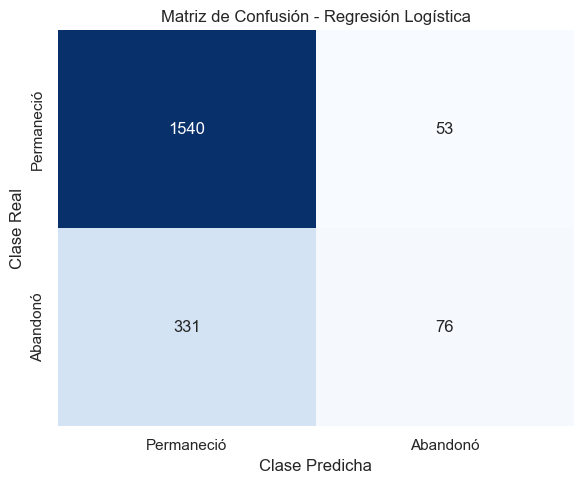

In [29]:
# Gráfico de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_logistica,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "Regresión Logística"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

**Interpretación de la Regresión Logística Baseline**

La Regresión Logística mantuvo resultados consistentes con los obtenidos durante el Avance 1.

El modelo presentó una Accuracy cercana al 81%. Sin embargo, esta métrica debe interpretarse con cautela debido al desbalance existente entre las clases.

La Precision fue cercana al 59%, lo que indica que una parte importante de los clientes clasificados como posibles abandonos efectivamente pertenecía a la clase positiva.

La principal limitación se observó en Recall. El modelo detectó aproximadamente el 19% de los clientes que realmente abandonaron el banco.

La matriz de confusión permitió observar una cantidad elevada de falsos negativos. Esto significa que numerosos clientes que abandonaron fueron clasificados como clientes que permanecerían.

Por lo tanto, aunque la Regresión Logística constituye un modelo interpretable y estable, presenta una capacidad limitada para identificar a la clase positiva.

Los siguientes modelos serán comparados con este baseline para determinar si logran mejorar la detección del churn sin generar un deterioro excesivo en las demás métricas.

#### 9. Random Forest

Random Forest es un algoritmo de ensamble basado en la técnica de Bagging.

El modelo construye múltiples árboles de decisión utilizando:

- Diferentes muestras aleatorias del conjunto de entrenamiento.
- Diferentes subconjuntos de variables en cada división.

Cada árbol genera una predicción individual y la clasificación final se determina mediante la votación conjunta del bosque.

La combinación de múltiples árboles permite reducir la variabilidad asociada a un árbol individual y construir un modelo más estable.

A diferencia de la Regresión Logística, Random Forest puede capturar:

- Relaciones no lineales.
- Interacciones entre variables.
- Patrones complejos sin necesidad de definirlos manualmente.

In [30]:
# Importación del modelo

from sklearn.ensemble import (
    RandomForestClassifier
)

print(
    "Random Forest "
    "importado correctamente."
)

Random Forest importado correctamente.


##### 9.1 Configuración del Modelo

Random Forest será entrenado utilizando una configuración inicial controlada.

Los principales hiperparámetros serán:

- `n_estimators=300`: cantidad de árboles que formarán el bosque.
- `max_depth=10`: profundidad máxima permitida para cada árbol.
- `min_samples_leaf=2`: cantidad mínima de observaciones necesarias en una hoja.
- `max_features="sqrt"`: cantidad de variables consideradas aleatoriamente en cada división.
- `bootstrap=True`: utiliza muestreo aleatorio con reemplazo.
- `random_state=42`: garantiza la reproducibilidad.

Los parámetros `max_depth` y `min_samples_leaf` limitan parcialmente la complejidad de los árboles y ayudan a reducir el riesgo de sobreajuste.

No se aplicará Grid Search sobre Random Forest, debido a que la optimización obligatoria del Avance 2 corresponde únicamente a XGBoost.

In [31]:
# Creación del Modelo Random Forest

modelo_random_forest = (
    RandomForestClassifier(

        n_estimators=300,

        max_depth=10,

        min_samples_leaf=2,

        max_features="sqrt",

        bootstrap=True,

        random_state=RANDOM_STATE,

        n_jobs=-1

    )
)

print(
    "Modelo Random Forest "
    "creado correctamente."
)

Modelo Random Forest creado correctamente.


##### 9.2 Construcción del Pipeline

El Pipeline de Random Forest incluirá:

1. El mismo preprocesamiento utilizado en la Regresión Logística.
2. El modelo Random Forest.

Aunque los modelos basados en árboles no requieren obligatoriamente que las variables numéricas sean estandarizadas, se mantendrá el mismo esquema de transformación para garantizar consistencia entre los modelos y facilitar la comparación posterior.

Las variables categóricas serán transformadas mediante One-Hot Encoding y las variables binarias serán conservadas sin modificaciones.

In [32]:
# Construcción del Pipeline de Random Forest

pipeline_random_forest = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_random_forest
        )

    ]

)

print(
    "Pipeline de Random Forest "
    "creado correctamente."
)

Pipeline de Random Forest creado correctamente.


##### 9.3 Entrenamiento y Evaluación

Random Forest será evaluado mediante el mismo protocolo utilizado para la Regresión Logística:

- Validación cruzada estratificada con cinco pliegues.
- Cálculo de Accuracy.
- Cálculo de Precision.
- Cálculo de Recall.
- Cálculo de F1-Score.
- Cálculo de ROC-AUC.
- Cálculo de PR-AUC.

Posteriormente, el modelo será entrenado utilizando el conjunto completo de entrenamiento y evaluado sobre los 2.000 clientes reservados para prueba.

In [33]:
# Evaluación de Random Forest

resultado_random_forest = evaluar_modelo(

    nombre_modelo=(
        "Random Forest"
    ),

    pipeline_modelo=(
        pipeline_random_forest
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "Random Forest "
    "evaluado correctamente."
)

Random Forest evaluado correctamente.


In [34]:
# Almacenamiento de resultados

resultados_modelos[

    "Random Forest"

] = resultado_random_forest

print(
    "Resultados de Random Forest "
    "almacenados correctamente."
)

Resultados de Random Forest almacenados correctamente.


In [35]:
# Visualización de resultados

mostrar_resultados(

    resultado_random_forest

)

MODELO: Random Forest

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.79,0.03
2,Recall,0.44,0.02
3,F1-Score,0.56,0.03
4,ROC-AUC,0.86,0.01
5,PR-AUC (AP),0.69,0.02



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71,0.69,0.02


##### 9.4 Matriz de Confusión

La matriz de confusión permitirá observar cómo Random Forest clasifica a los clientes pertenecientes a ambas clases.

Se analizarán especialmente:

- Los verdaderos positivos.
- Los falsos negativos.

Los falsos negativos representan clientes que realmente abandonaron el banco, pero fueron clasificados como clientes que permanecerían.

Reducir este tipo de error es importante para mejorar la capacidad de detección del churn.

In [36]:
# Recuperación de la Matriz de Confusión

matriz_random_forest = (

    resultado_random_forest[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_rf, fp_rf, fn_rf, tp_rf = (

    matriz_random_forest
    .ravel()

)

# Creación de la tabla

tabla_matriz_random_forest = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_rf,

            fp_rf,

            fn_rf,

            tp_rf

        ]

    })
)

tabla_matriz_random_forest

,Resultado,Cantidad
0,Verdaderos negativos,1552
1,Falsos positivos,41
2,Falsos negativos,226
3,Verdaderos positivos,181


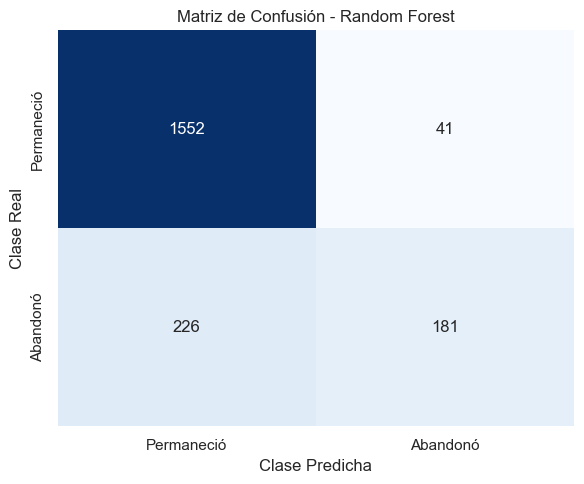

In [37]:
# Visualización de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_random_forest,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "Random Forest"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 9.5 Comparación Inicial con la Regresión Logística

Random Forest será comparado directamente con la Regresión Logística baseline.

La comparación incluirá:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

La columna de diferencia mostrará cuánto aumentó o disminuyó cada métrica respecto del modelo baseline.

Una diferencia positiva representa una mejora de Random Forest, mientras que una diferencia negativa representa una disminución.

In [38]:
# Métricas utilizadas para comparar

metricas_comparacion = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

# Valores de Regresión Logística

valores_logistica = [

    resultado_logistico[
        "metricas_test"
    ][metrica]

    for metrica
    in metricas_comparacion

]

# Valores de Random Forest

valores_random_forest = [

    resultado_random_forest[
        "metricas_test"
    ][metrica]

    for metrica
    in metricas_comparacion

]

# Creación de la tabla

comparacion_logistica_rf = (
    pd.DataFrame({

        "Métrica": (
            metricas_comparacion
        ),

        "Regresión Logística": (
            valores_logistica
        ),

        "Random Forest": (
            valores_random_forest
        )

    })
)

# Diferencia respecto del baseline

comparacion_logistica_rf[

    "Diferencia RF - Baseline"

] = (

    comparacion_logistica_rf[

        "Random Forest"

    ]

    - comparacion_logistica_rf[

        "Regresión Logística"

    ]

)

# Redondeo

columnas_resultados = [

    "Regresión Logística",

    "Random Forest",

    "Diferencia RF - Baseline"

]

comparacion_logistica_rf[

    columnas_resultados

] = (

    comparacion_logistica_rf[

        columnas_resultados

    ]

    .round(4)

)

comparacion_logistica_rf

,Métrica,Regresión Logística,Random Forest,Diferencia RF - Baseline
0,Accuracy,0.81,0.87,0.06
1,Precision,0.59,0.82,0.23
2,Recall,0.19,0.44,0.26
3,F1-Score,0.28,0.58,0.29
4,ROC-AUC,0.77,0.86,0.09
5,PR-AUC (AP),0.48,0.71,0.23


##### 9.6 Comparación entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida mediante validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba.

Una diferencia pequeña entre ambos resultados puede indicar que el modelo mantiene un comportamiento estable frente a datos no utilizados durante el entrenamiento.

Una diferencia elevada debe analizarse con mayor atención, ya que podría señalar sensibilidad a la partición de los datos o problemas de generalización.

In [39]:
# Comparación entre Validación Cruzada y Prueba

tabla_estabilidad_rf = pd.DataFrame({

    "Modelo": [

        "Random Forest"

    ],

    "PR-AUC media CV": [

        resultado_random_forest[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_random_forest[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_random_forest[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

# Diferencia entre prueba y CV

tabla_estabilidad_rf[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_rf[

        "PR-AUC prueba"

    ]

    - tabla_estabilidad_rf[

        "PR-AUC media CV"

    ]

)

# Redondeo

columnas_estabilidad = (

    tabla_estabilidad_rf

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_rf[

    columnas_estabilidad

] = (

    tabla_estabilidad_rf[

        columnas_estabilidad

    ]

    .round(4)

)

tabla_estabilidad_rf

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,Random Forest,0.69,0.02,0.71,0.02


**Interpretación de Random Forest**

Random Forest presentó un rendimiento superior a la Regresión Logística baseline en todas las métricas evaluadas.

En el Conjunto de Prueba obtuvo:

- Accuracy: 0,87.
- Precision: 0,82.
- Recall: 0,44.
- F1-Score: 0,58.
- ROC-AUC: 0,86.
- PR-AUC: 0,71.

La mejora en **PR-AUC** fue especialmente relevante, ya que aumentó desde 0,48 en la Regresión Logística hasta 0,71 en Random Forest. Esto indica una mejor capacidad para identificar y priorizar clientes con riesgo de abandono dentro de un problema con clases desbalanceadas.

También se observó una mejora importante en **Recall**. La Regresión Logística detectaba aproximadamente el 19% de los clientes que abandonaron, mientras que Random Forest detectó cerca del 44%.

La **Matriz de Confusión** mostró:

- 1.552 verdaderos negativos.
- 41 falsos positivos.
- 226 falsos negativos.
- 181 verdaderos positivos.

Respecto del modelo baseline, **Random Forest** identificó correctamente 105 clientes adicionales que abandonaron y redujo los falsos negativos de 331 a 226.

La mejora en Recall no produjo una reducción de Precision. Por el contrario, **Precision** aumentó aproximadamente desde 0,59 hasta 0,82 y los falsos positivos disminuyeron de 53 a 41.

Los resultados obtenidos mediante **Validación Cruzada** fueron consistentes con la evaluación sobre el conjunto de prueba. La PR-AUC promedio de validación fue de 0,69, con un desvío de 0,02, mientras que en prueba alcanzó 0,71.

La pequeña diferencia entre ambos resultados y los bajos desvíos observados sugieren que el modelo presenta un comportamiento estable y no muestra señales evidentes de sobreajuste.

Random Forest constituye una mejora importante respecto de la Regresión Logística. Sin embargo, todavía no puede considerarse el modelo final, ya que deberá compararse con XGBoost, LightGBM, CatBoost, XGBoost optimizado y Stacking.

#### 10. XGBoost

**Extreme Gradient Boosting** (abreviado: XGBoost), es un algoritmo de ensamble basado en Gradient Boosting.

A diferencia de Random Forest, donde los árboles se entrenan de manera independiente, XGBoost construye los árboles de forma secuencial.

Cada nuevo árbol intenta corregir parte de los errores cometidos por los árboles anteriores. Las predicciones se combinan progresivamente hasta formar un modelo final más potente.

Entre sus principales características se encuentran:

- Aprendizaje secuencial.
- Control de la contribución de cada árbol mediante `learning_rate`.
- Regularización L1 y L2.
- Control de la profundidad de los árboles.
- Submuestreo de registros y variables.
- Capacidad para capturar relaciones no lineales e interacciones complejas.

En esta primera implementación se utilizará una configuración inicial sin optimización de hiperparámetros.

Posteriormente, XGBoost será optimizado mediante Grid Search, tal como establece la consigna del Avance 2.

In [40]:
# Importación de XGBoost

import xgboost

from xgboost import (
    XGBClassifier
)

print(
    "XGBoost importado correctamente."
)

print(
    f"Versión instalada: "
    f"{xgboost.__version__}"
)

XGBoost importado correctamente.
Versión instalada: 3.3.0


##### 10.1 Configuración inicial de XGBoost

Se utilizará una configuración inicial controlada antes de realizar la optimización mediante Grid Search.

Los principales hiperparámetros serán:

- `n_estimators=300`: cantidad máxima de árboles construidos.
- `learning_rate=0.05`: contribución de cada nuevo árbol al modelo final.
- `max_depth=4`: profundidad máxima de cada árbol.
- `subsample=0.80`: proporción de registros utilizada para construir cada árbol.
- `colsample_bytree=0.80`: proporción de variables utilizada en cada árbol.
- `reg_alpha=0`: regularización L1.
- `reg_lambda=1`: regularización L2.
- `objective="binary:logistic"`: función objetivo correspondiente a una clasificación binaria.
- `eval_metric="logloss"`: métrica interna utilizada durante el entrenamiento.

La configuración busca limitar la complejidad inicial mediante árboles relativamente poco profundos, una tasa de aprendizaje reducida y el uso parcial de observaciones y variables.

No se aplicará optimización en esta etapa. Los hiperparámetros serán ajustados posteriormente mediante Grid Search.

In [41]:
# Creación del Modelo XGBoost inicial

modelo_xgboost_inicial = XGBClassifier(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=4,

    subsample=0.80,

    colsample_bytree=0.80,

    reg_alpha=0,

    reg_lambda=1,

    objective="binary:logistic",

    eval_metric="logloss",

    importance_type="gain",

    random_state=RANDOM_STATE,

    n_jobs=1,

    verbosity=0

)

print(
    "Modelo XGBoost inicial "
    "creado correctamente."
)

Modelo XGBoost inicial creado correctamente.


##### 10.2 Control de Complejidad

XGBoost incluye diferentes mecanismos para reducir el riesgo de sobreajuste.

En esta configuración inicial se utilizarán:

- Profundidad limitada mediante `max_depth`.
- Tasa de aprendizaje reducida mediante `learning_rate`.
- Submuestreo de observaciones mediante `subsample`.
- Submuestreo de variables mediante `colsample_bytree`.
- Regularización L2 mediante `reg_lambda`.

XGBoost también permite aplicar `early stopping`, una técnica que detiene el entrenamiento cuando el rendimiento sobre un conjunto de validación deja de mejorar.

En esta implementación inicial no se utilizará early stopping, debido a que la evaluación se realizará mediante un Pipeline y validación cruzada estratificada.

##### 10.3 Construcción del Pipeline

El Pipeline incluirá:

1. El mismo preprocesamiento utilizado en los modelos anteriores.
2. El modelo XGBoost.

Mantener un esquema común hace que todos los algoritmos reciban las mismas variables y transformaciones.

Aunque XGBoost no requiere necesariamente que las variables numéricas estén estandarizadas, se conservará el mismo preprocesamiento para mantener consistencia metodológica y facilitar la comparación entre modelos.

In [42]:
# Construcción del Pipeline de XGBoost inicial

pipeline_xgboost_inicial = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_xgboost_inicial
        )

    ]

)

print(
    "Pipeline de XGBoost inicial "
    "creado correctamente."
)

Pipeline de XGBoost inicial creado correctamente.


##### 10.4 Entrenamiento y Evaluación

XGBoost será evaluado mediante el mismo protocolo aplicado a la Regresión Logística y Random Forest.

Se utilizarán:

- Validación cruzada estratificada con cinco pliegues.
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

Después de la validación cruzada, el modelo será entrenado utilizando los 8.000 registros del conjunto de entrenamiento y evaluado sobre los 2.000 clientes reservados para prueba.

In [43]:
# Evaluación de XGBoost inicial

resultado_xgboost_inicial = evaluar_modelo(

    nombre_modelo=(
        "XGBoost inicial"
    ),

    pipeline_modelo=(
        pipeline_xgboost_inicial
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "XGBoost inicial "
    "evaluado correctamente."
)

XGBoost inicial evaluado correctamente.


In [44]:
# Almacenamiento de resultados

resultados_modelos[

    "XGBoost inicial"

] = resultado_xgboost_inicial

print(
    "Resultados de XGBoost inicial "
    "almacenados correctamente."
)

Resultados de XGBoost inicial almacenados correctamente.


In [45]:
# Visualización de resultados

mostrar_resultados(

    resultado_xgboost_inicial

)

MODELO: XGBoost inicial

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.76,0.02
2,Recall,0.48,0.03
3,F1-Score,0.59,0.03
4,ROC-AUC,0.87,0.01
5,PR-AUC (AP),0.70,0.02



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72,0.70,0.02


##### 10.5 Matriz de Confusión

La matriz de confusión permitirá analizar los aciertos y errores de XGBoost sobre el conjunto de prueba.

Se prestará especial atención a:

- Verdaderos positivos.
- Falsos negativos.
- Cambios respecto de Random Forest.

La reducción de falsos negativos representa una mejora en la capacidad para detectar clientes que realmente abandonaron.

In [46]:
# Recuperación de la Matriz de Confusión

matriz_xgboost_inicial = (

    resultado_xgboost_inicial[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_xgb, fp_xgb, fn_xgb, tp_xgb = (

    matriz_xgboost_inicial
    .ravel()

)

# Creación de tabla

tabla_matriz_xgboost_inicial = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_xgb,

            fp_xgb,

            fn_xgb,

            tp_xgb

        ]

    })
)

tabla_matriz_xgboost_inicial

,Resultado,Cantidad
0,Verdaderos negativos,1537
1,Falsos positivos,56
2,Falsos negativos,208
3,Verdaderos positivos,199


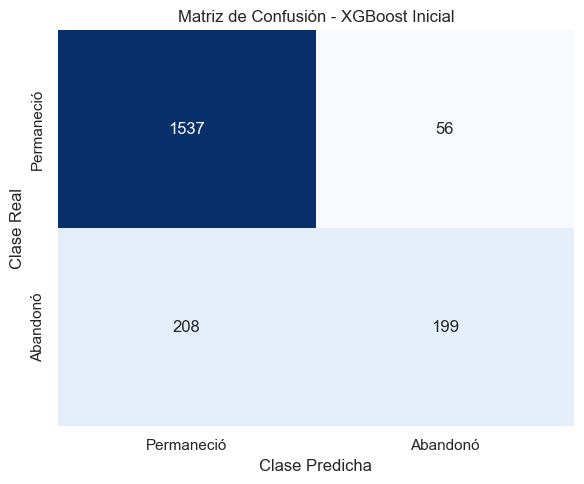

In [47]:
# Visualización de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_xgboost_inicial,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "XGBoost Inicial"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 10.6 Comparación Inicial de Modelos

Se compararán los resultados obtenidos por:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.

La comparación permitirá determinar si XGBoost mejora el desempeño respecto del modelo baseline y del primer modelo de ensamble evaluado.

La métrica principal continuará siendo PR-AUC.

In [48]:
# Modelos incluidos en la comparación

modelos_comparacion_inicial = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial"

]

# Construcción de tabla

tabla_comparacion_inicial = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_comparacion_inicial

    ]

)

# Selección de columnas

tabla_comparacion_inicial = (

    tabla_comparacion_inicial[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

# Redondeo

columnas_metricas = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

tabla_comparacion_inicial[

    columnas_metricas

] = (

    tabla_comparacion_inicial[

        columnas_metricas

    ]

    .round(4)

)

tabla_comparacion_inicial

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48
1,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71
2,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72


##### 10.7 Diferencias Respecto de los Modelos Anteriores

Se calculará la diferencia entre las métricas de XGBoost y las obtenidas por:

- Regresión Logística.
- Random Forest.

Un valor positivo indicará una mejora de XGBoost.

Un valor negativo indicará una disminución respecto del modelo utilizado como referencia.

In [49]:
# Métricas utilizadas

metricas_diferencia = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

# Construcción de tabla

comparacion_diferencias_xgb = (
    pd.DataFrame({

        "Métrica": (
            metricas_diferencia
        ),

        "XGBoost inicial": [

            resultado_xgboost_inicial[
                "metricas_test"
            ][metrica]

            for metrica
            in metricas_diferencia

        ],

        "Diferencia XGB - Baseline": [

            (
                resultado_xgboost_inicial[
                    "metricas_test"
                ][metrica]

                -

                resultado_logistico[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia XGB - RF": [

            (
                resultado_xgboost_inicial[
                    "metricas_test"
                ][metrica]

                -

                resultado_random_forest[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ]

    })
)

# Redondeo

columnas_numericas_xgb = (

    comparacion_diferencias_xgb

    .select_dtypes(
        include="number"
    )

    .columns

)

comparacion_diferencias_xgb[

    columnas_numericas_xgb

] = (

    comparacion_diferencias_xgb[

        columnas_numericas_xgb

    ]

    .round(4)

)

comparacion_diferencias_xgb

,Métrica,XGBoost inicial,Diferencia XGB - Baseline,Diferencia XGB - RF
0,Accuracy,0.87,0.06,0.00
1,Precision,0.78,0.19,-0.03
2,Recall,0.49,0.30,0.04
3,F1-Score,0.60,0.32,0.03
4,ROC-AUC,0.87,0.09,0.00
5,PR-AUC (AP),0.72,0.24,0.01


##### 10.8 Estabilidad entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida durante la validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba.

La comparación permitirá analizar si el comportamiento del modelo se mantiene estable frente a datos no utilizados durante el entrenamiento.

In [50]:
# Comparación de estabilidad

tabla_estabilidad_xgb = pd.DataFrame({

    "Modelo": [

        "XGBoost inicial"

    ],

    "PR-AUC media CV": [

        resultado_xgboost_inicial[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_xgboost_inicial[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_xgboost_inicial[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

# Diferencia

tabla_estabilidad_xgb[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_xgb[

        "PR-AUC prueba"

    ]

    -

    tabla_estabilidad_xgb[

        "PR-AUC media CV"

    ]

)

# Redondeo

columnas_estabilidad_xgb = (

    tabla_estabilidad_xgb

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_xgb[

    columnas_estabilidad_xgb

] = (

    tabla_estabilidad_xgb[

        columnas_estabilidad_xgb

    ]

    .round(4)

)

tabla_estabilidad_xgb

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,XGBoost inicial,0.70,0.02,0.72,0.02


**Interpretación de XGBoost Inicial**

**XGBoost inicial** presentó un rendimiento superior a la **Regresión Logística baseline** y una mejora leve respecto de **Random Forest** en la mayoría de las métricas principales.

En el conjunto de prueba obtuvo:

- Accuracy: 0,87.
- Precision: 0,78.
- Recall: 0,49.
- F1-Score: 0,60.
- ROC-AUC: 0,87.
- PR-AUC: 0,72.

La **PR-AUC** aumentó desde 0,48 en la Regresión Logística hasta 0,72 en XGBoost. Esta mejora indica una mayor capacidad para identificar y priorizar clientes con riesgo de abandono dentro de un problema con clases desbalanceadas.

También se observó una mejora importante en **Recall**. La Regresión Logística detectaba aproximadamente el 19% de los clientes que abandonaron, mientras que XGBoost identificó cerca del 49%.

La **Matriz de Confusión** mostró:

- 1.537 verdaderos negativos.
- 56 falsos positivos.
- 208 falsos negativos.
- 199 verdaderos positivos.

Respecto de la Regresión Logística, XGBoost identificó correctamente 123 clientes adicionales que abandonaron y redujo los falsos negativos de 331 a 208.

Al compararlo con Random Forest, XGBoost presentó un Recall mayor, pasando aproximadamente de 0,44 a 0,49. Esto permitió detectar 18 clientes adicionales que abandonaron y reducir los falsos negativos de 226 a 208.

Sin embargo, Random Forest obtuvo una **Precision** superior. XGBoost aumentó los falsos positivos de 41 a 56, lo que refleja un intercambio entre una mayor capacidad de detección y una menor precisión de las alertas positivas.

La **PR-AUC** de XGBoost fue de 0,72, ligeramente superior al valor de 0,71 obtenido por Random Forest. Debido a que la diferencia es pequeña, todavía no puede afirmarse que exista una ventaja amplia entre ambos modelos.

Los resultados de **Validación Cruzada** fueron consistentes con la evaluación sobre prueba. La PR-AUC promedio fue de 0,70, con un desvío de 0,02, mientras que en el conjunto de prueba alcanzó 0,72.

La pequeña diferencia entre validación y prueba y los bajos desvíos observados sugieren que el modelo presenta un comportamiento estable y no muestra señales evidentes de sobreajuste.

**XGBoost inicial** constituye actualmente el modelo con mejor PR-AUC, aunque deberá compararse posteriormente con LightGBM, CatBoost, XGBoost optimizado mediante Grid Search y Stacking.

#### 11. LightGBM

**LightGBM**, abreviatura de *Light Gradient Boosting Machine*, es un algoritmo basado en Gradient Boosting diseñado para mejorar la velocidad y la eficiencia del entrenamiento.

Al igual que XGBoost, construye árboles de manera secuencial. Cada nuevo árbol intenta reducir los errores que permanecen después de los modelos anteriores.

Entre sus principales características se encuentran:

- Entrenamiento eficiente.
- Bajo consumo de memoria.
- Capacidad para trabajar con grandes volúmenes de datos.
- Crecimiento de árboles basado en las hojas con mayor potencial de reducción del error.
- Manejo nativo de variables categóricas.
- Capacidad para capturar relaciones no lineales e interacciones complejas.

En este proyecto se utilizará el mismo esquema de preprocesamiento aplicado a los modelos anteriores para mantener una comparación consistente.

LightGBM será entrenado mediante una configuración inicial y no se aplicará Grid Search.

In [51]:
# Importación de LightGBM

import lightgbm

from lightgbm import (
    LGBMClassifier
)

print(
    "LightGBM importado correctamente."
)

print(
    f"Versión instalada: "
    f"{lightgbm.__version__}"
)

LightGBM importado correctamente.
Versión instalada: 4.6.0


##### 11.1 Configuración Inicial de LightGBM

Se utilizará una configuración inicial controlada.

Los principales hiperparámetros serán:

- `n_estimators=300`: cantidad de árboles construidos.
- `learning_rate=0.05`: contribución de cada nuevo árbol.
- `num_leaves=31`: cantidad máxima de hojas por árbol.
- `min_child_samples=20`: cantidad mínima de observaciones necesarias dentro de una hoja.
- `subsample=0.80`: proporción de registros utilizada en cada iteración.
- `subsample_freq=1`: activa el submuestreo de registros.
- `colsample_bytree=0.80`: proporción de variables utilizada por árbol.
- `reg_alpha=0`: regularización L1.
- `reg_lambda=1`: regularización L2.
- `objective="binary"`: función objetivo correspondiente a clasificación binaria.

Los hiperparámetros `num_leaves` y `min_child_samples` permiten controlar la complejidad de los árboles y reducir el riesgo de sobreajuste.

No se realizará una búsqueda de hiperparámetros sobre LightGBM, ya que la consigna establece que la optimización debe aplicarse solamente a XGBoost.

In [52]:
# Creación del Modelo LightGBM inicial

modelo_lightgbm = LGBMClassifier(

    n_estimators=300,

    learning_rate=0.05,

    num_leaves=31,

    min_child_samples=20,

    subsample=0.80,

    subsample_freq=1,

    colsample_bytree=0.80,

    reg_alpha=0,

    reg_lambda=1,

    objective="binary",

    importance_type="gain",

    random_state=RANDOM_STATE,

    n_jobs=1,

    verbosity=-1

)

print(
    "Modelo LightGBM "
    "creado correctamente."
)

Modelo LightGBM creado correctamente.


##### 11.2 Tratamiento de Variables Categóricas

LightGBM puede trabajar de manera nativa con variables categóricas.

Sin embargo, en este proyecto se utilizará el mismo preprocesamiento aplicado a Regresión Logística, Random Forest y XGBoost:

- Estandarización de variables numéricas.
- One-Hot Encoding de variables categóricas.
- Conservación directa de variables binarias.

La decisión permite:

- Mantener las mismas variables transformadas.
- Facilitar una comparación consistente.
- Evitar que cada modelo reciba una representación diferente de los datos.
- Simplificar la posterior construcción del modelo Stacking.

Por lo tanto, en esta implementación no se utilizará el manejo categórico nativo de LightGBM.

##### 11.3 Construcción del Pipeline

El Pipeline incluirá:

1. El preprocesamiento utilizado en los modelos anteriores.
2. El modelo LightGBM.

Aunque los modelos basados en árboles no requieren necesariamente el escalamiento de las variables numéricas, se mantendrá una transformación común para conservar consistencia metodológica.

In [53]:
# Construcción del Pipeline de LightGBM

pipeline_lightgbm = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_lightgbm
        )

    ]

)

print(
    "Pipeline de LightGBM "
    "creado correctamente."
)

Pipeline de LightGBM creado correctamente.


##### 11.4 Entrenamiento y Evaluación

LightGBM será evaluado mediante el mismo protocolo aplicado a los modelos anteriores.

Se utilizarán:

- Validación cruzada estratificada con cinco pliegues.
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

Después de la validación cruzada, el modelo será entrenado utilizando los 8.000 registros del conjunto de entrenamiento y evaluado sobre los 2.000 clientes reservados para prueba.

In [54]:
# Evaluación de LightGBM

resultado_lightgbm = evaluar_modelo(

    nombre_modelo=(
        "LightGBM"
    ),

    pipeline_modelo=(
        pipeline_lightgbm
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "LightGBM "
    "evaluado correctamente."
)

LightGBM evaluado correctamente.


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [55]:
# Almacenamiento de resultados

resultados_modelos[

    "LightGBM"

] = resultado_lightgbm

print(
    "Resultados de LightGBM "
    "almacenados correctamente."
)

Resultados de LightGBM almacenados correctamente.


In [56]:
# Visualización de resultados

mostrar_resultados(

    resultado_lightgbm

)

MODELO: LightGBM

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.72,0.02
2,Recall,0.50,0.03
3,F1-Score,0.59,0.03
4,ROC-AUC,0.86,0.01
5,PR-AUC (AP),0.69,0.03



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70,0.69,0.03


##### 11.5 Matriz de Confusión

La matriz de confusión permitirá analizar los aciertos y errores de LightGBM sobre el conjunto de prueba.

Se observarán especialmente:

- La cantidad de verdaderos positivos.
- La cantidad de falsos negativos.
- Los cambios respecto de Random Forest y XGBoost inicial.

Una reducción de falsos negativos representa una mayor capacidad para detectar clientes que realmente abandonaron.

In [57]:
# Recuperación de la Matriz de Confusión

matriz_lightgbm = (

    resultado_lightgbm[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_lgbm, fp_lgbm, fn_lgbm, tp_lgbm = (

    matriz_lightgbm
    .ravel()

)

# Creación de tabla

tabla_matriz_lightgbm = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_lgbm,

            fp_lgbm,

            fn_lgbm,

            tp_lgbm

        ]

    })
)

tabla_matriz_lightgbm

,Resultado,Cantidad
0,Verdaderos negativos,1522
1,Falsos positivos,71
2,Falsos negativos,206
3,Verdaderos positivos,201


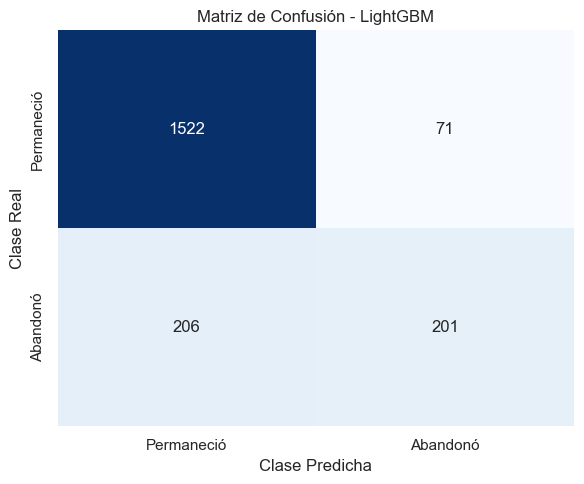

In [58]:
# Gráfico de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_lightgbm,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "LightGBM"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 11.6 Comparación Inicial de Modelos

Se compararán los resultados obtenidos por:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.
- LightGBM.

La métrica principal continuará siendo PR-AUC.

También se analizarán Recall, F1-Score y ROC-AUC para evaluar la capacidad de detectar clientes que abandonaron y el equilibrio general entre las métricas.

In [59]:
# Modelos incluidos en la Comparación

modelos_comparacion_lightgbm = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial",

    "LightGBM"

]

# Construcción de tabla

tabla_comparacion_lightgbm = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_comparacion_lightgbm

    ]

)

# Selección de columnas

tabla_comparacion_lightgbm = (

    tabla_comparacion_lightgbm[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

# Redondeo

columnas_metricas = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

tabla_comparacion_lightgbm[

    columnas_metricas

] = (

    tabla_comparacion_lightgbm[

        columnas_metricas

    ]

    .round(4)

)

tabla_comparacion_lightgbm

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48
1,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71
2,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72
3,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70


##### 11.7 Diferencias Respecto de los Modelos Anteriores

Se calcularán las diferencias entre LightGBM y:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.

Los valores positivos representarán una mejora de LightGBM.

Los valores negativos indicarán una reducción respecto del modelo utilizado como referencia.

In [60]:
# Métricas utilizadas

metricas_diferencia = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

# Construcción de tabla

comparacion_diferencias_lgbm = (
    pd.DataFrame({

        "Métrica": (
            metricas_diferencia
        ),

        "LightGBM": [

            resultado_lightgbm[
                "metricas_test"
            ][metrica]

            for metrica
            in metricas_diferencia

        ],

        "Diferencia LGBM - Baseline": [

            (
                resultado_lightgbm[
                    "metricas_test"
                ][metrica]

                -

                resultado_logistico[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia LGBM - RF": [

            (
                resultado_lightgbm[
                    "metricas_test"
                ][metrica]

                -

                resultado_random_forest[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia LGBM - XGB": [

            (
                resultado_lightgbm[
                    "metricas_test"
                ][metrica]

                -

                resultado_xgboost_inicial[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ]

    })
)

# Redondeo

columnas_numericas_lgbm = (

    comparacion_diferencias_lgbm

    .select_dtypes(
        include="number"
    )

    .columns

)

comparacion_diferencias_lgbm[

    columnas_numericas_lgbm

] = (

    comparacion_diferencias_lgbm[

        columnas_numericas_lgbm

    ]

    .round(4)

)

comparacion_diferencias_lgbm

,Métrica,LightGBM,Diferencia LGBM - Baseline,Diferencia LGBM - RF,Diferencia LGBM - XGB
0,Accuracy,0.86,0.05,-0.01,-0.01
1,Precision,0.74,0.15,-0.08,-0.04
2,Recall,0.49,0.31,0.05,0.00
3,F1-Score,0.59,0.31,0.02,-0.01
4,ROC-AUC,0.86,0.08,-0.01,-0.01
5,PR-AUC (AP),0.70,0.22,-0.01,-0.02


##### 11.8 Estabilidad entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida mediante validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba.

Una diferencia pequeña indicará que el comportamiento del modelo se mantiene estable frente a datos no utilizados durante el entrenamiento.

In [61]:
# Comparación de estabilidad

tabla_estabilidad_lgbm = pd.DataFrame({

    "Modelo": [

        "LightGBM"

    ],

    "PR-AUC media CV": [

        resultado_lightgbm[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_lightgbm[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_lightgbm[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

# Diferencia

tabla_estabilidad_lgbm[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_lgbm[

        "PR-AUC prueba"

    ]

    -

    tabla_estabilidad_lgbm[

        "PR-AUC media CV"

    ]

)

# Redondeo

columnas_estabilidad_lgbm = (

    tabla_estabilidad_lgbm

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_lgbm[

    columnas_estabilidad_lgbm

] = (

    tabla_estabilidad_lgbm[

        columnas_estabilidad_lgbm

    ]

    .round(4)

)

tabla_estabilidad_lgbm

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,LightGBM,0.69,0.03,0.70,0.01


**Interpretación de LightGBM**

LightGBM presentó un rendimiento claramente superior a la Regresión Logística baseline y resultados competitivos respecto de Random Forest y XGBoost inicial.

En el conjunto de prueba obtuvo:

- Accuracy: 0,86.
- Precision: 0,74.
- Recall: 0,49.
- F1-Score: 0,59.
- ROC-AUC: 0,86.
- PR-AUC: 0,70.

La **PR-AUC** aumentó desde 0,48 en la Regresión Logística hasta 0,70 en LightGBM. Esto indica una mejora importante en la capacidad para identificar y priorizar clientes con riesgo de abandono dentro de un problema con clases desbalanceadas.

También se observó una mejora considerable en **Recall**. La Regresión Logística detectaba aproximadamente el 19% de los clientes que abandonaron, mientras que LightGBM identificó cerca del 49%.

La **Matriz de Confusión** mostró:

- 1.522 verdaderos negativos.
- 71 falsos positivos.
- 206 falsos negativos.
- 201 verdaderos positivos.

Respecto de la **Regresión Logística**, LightGBM identificó correctamente 125 clientes adicionales que abandonaron y redujo los falsos negativos de 331 a 206.

La mejora en la detección produjo un aumento de los falsos positivos, que pasaron de 53 a 71. Este resultado refleja un intercambio entre una mayor capacidad para detectar clientes en riesgo y una mayor cantidad de alertas incorrectas.

Al compararlo con **Random Forest**, LightGBM obtuvo un Recall superior y detectó 20 clientes adicionales que abandonaron. Sin embargo, presentó una Precision menor y generó 30 falsos positivos adicionales. La PR-AUC fue ligeramente inferior, con valores de 0,70 para LightGBM y 0,71 para Random Forest.

Respecto de **XGBoost inicial**, LightGBM presentó resultados similares en Recall, aunque obtuvo valores inferiores de Precision, F1-Score, ROC-AUC y PR-AUC. XGBoost mantuvo la mejor PR-AUC hasta el momento, con un valor de 0,72.

Los resultados de **Validación Cruzada** fueron consistentes con la evaluación sobre el conjunto de prueba. La PR-AUC promedio fue de 0,69, con un desvío de 0,03, mientras que en prueba alcanzó 0,70.

La pequeña diferencia entre validación y prueba y los bajos desvíos observados sugieren que **LightGBM** presenta un comportamiento estable y no muestra señales evidentes de sobreajuste.

LightGBM constituye una mejora importante respecto del modelo baseline, aunque XGBoost inicial continúa siendo el modelo con mejor PR-AUC entre los algoritmos evaluados hasta el momento.

#### 12. CatBoost

**CatBoost**, abreviatura de *Categorical Boosting*, es un algoritmo basado en Gradient Boosting.

Al igual que XGBoost y LightGBM, construye árboles de manera secuencial. Cada nuevo árbol intenta corregir los errores que permanecen después de las iteraciones anteriores.

CatBoost fue diseñado especialmente para trabajar con variables categóricas y reducir algunos problemas asociados a su codificación.

Entre sus principales características se encuentran:

- Manejo nativo de variables categóricas.
- Uso de técnicas internas para reducir el riesgo de fuga de información durante la codificación.
- Capacidad para capturar relaciones no lineales.
- Modelado de interacciones complejas entre variables.
- Incorporación de regularización para controlar el sobreajuste.
- Buen desempeño en datasets tabulares.

En este proyecto se utilizará el mismo preprocesamiento aplicado a los modelos anteriores para mantener una comparación consistente.

In [62]:
# Importación de CatBoost

import catboost

from catboost import (
    CatBoostClassifier
)

print(
    "CatBoost importado correctamente."
)

print(
    f"Versión instalada: "
    f"{catboost.__version__}"
)

CatBoost importado correctamente.
Versión instalada: 1.2.10


##### 12.1 Configuración Inicial de CatBoost

Se utilizará una configuración inicial controlada.

Los principales hiperparámetros serán:

- `iterations=300`: cantidad de iteraciones o árboles construidos.
- `learning_rate=0.05`: contribución de cada nuevo árbol.
- `depth=6`: profundidad máxima de los árboles.
- `l2_leaf_reg=3`: intensidad de la regularización L2.
- `loss_function="Logloss"`: función de pérdida utilizada para clasificación binaria.
- `eval_metric="Logloss"`: métrica interna utilizada durante el entrenamiento.
- `random_seed=42`: garantiza la reproducibilidad.
- `verbose=0`: evita mostrar información de cada iteración.

La configuración busca mantener una complejidad moderada mediante árboles de profundidad limitada, una tasa de aprendizaje reducida y regularización L2.

In [63]:
# Creación del modelo CatBoost inicial

modelo_catboost = CatBoostClassifier(

    iterations=300,

    learning_rate=0.05,

    depth=6,

    l2_leaf_reg=3,

    loss_function="Logloss",

    eval_metric="Logloss",

    random_seed=RANDOM_STATE,

    verbose=0,

    thread_count=1,

    allow_writing_files=False

)

print(
    "Modelo CatBoost "
    "creado correctamente."
)

Modelo CatBoost creado correctamente.


##### 12.2 Tratamiento de Variables Categóricas

CatBoost puede procesar variables categóricas directamente, sin necesidad de aplicar One-Hot Encoding.

Sin embargo, en este proyecto se mantendrá el mismo preprocesamiento utilizado en los modelos anteriores:

- Estandarización de variables numéricas.
- One-Hot Encoding de variables categóricas.
- Conservación directa de variables binarias.

Esta decisión permite:

- Mantener la misma representación de los datos.
- Garantizar que todos los modelos reciban las mismas variables.
- Facilitar una comparación metodológicamente consistente.
- Simplificar la posterior construcción del modelo Stacking.

Por lo tanto, en esta implementación no se aprovechará el manejo categórico nativo de CatBoost.

Esta decisión no implica que CatBoost requiera One-Hot Encoding, sino que se adopta un esquema común para el desarrollo comparativo del proyecto.

##### 12.3 Construcción del Pipeline

El Pipeline incluirá:

1. El mismo preprocesamiento utilizado en los modelos anteriores.
2. El modelo CatBoost.

El uso de un Pipeline garantiza que las transformaciones se ajusten únicamente con los datos correspondientes al entrenamiento de cada pliegue durante la validación cruzada.

In [64]:
# Construcción del Pipeline de CatBoost

pipeline_catboost = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_catboost
        )

    ]

)

print(
    "Pipeline de CatBoost "
    "creado correctamente."
)

Pipeline de CatBoost creado correctamente.


##### 12.4 Entrenamiento y Evaluación

CatBoost será evaluado mediante el mismo protocolo aplicado a los modelos anteriores.

Se utilizarán:

- Validación cruzada estratificada con cinco pliegues.
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

Después de la validación cruzada, el modelo será entrenado utilizando los 8.000 registros del conjunto de entrenamiento y evaluado sobre los 2.000 clientes reservados para prueba.

In [65]:
# Evaluación de CatBoost

resultado_catboost = evaluar_modelo(

    nombre_modelo=(
        "CatBoost"
    ),

    pipeline_modelo=(
        pipeline_catboost
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "CatBoost "
    "evaluado correctamente."
)

CatBoost evaluado correctamente.


In [66]:
# Almacenamiento de resultados

resultados_modelos[

    "CatBoost"

] = resultado_catboost

print(
    "Resultados de CatBoost "
    "almacenados correctamente."
)

Resultados de CatBoost almacenados correctamente.


In [67]:
# Visualización de resultados

mostrar_resultados(

    resultado_catboost

)

MODELO: CatBoost

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.75,0.03
2,Recall,0.48,0.02
3,F1-Score,0.59,0.03
4,ROC-AUC,0.87,0.01
5,PR-AUC (AP),0.70,0.02



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73,0.70,0.02


##### 12.5 Matriz de Confusión

La Matriz de Confusión permitirá analizar los aciertos y errores de CatBoost sobre el conjunto de prueba.

Se observarán especialmente:

- La cantidad de verdaderos positivos.
- La cantidad de falsos negativos.
- El equilibrio entre detección y falsas alertas.
- Los cambios respecto de XGBoost, Random Forest y LightGBM.

In [68]:
# Recuperación de la Matriz de Confusión

matriz_catboost = (

    resultado_catboost[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_cat, fp_cat, fn_cat, tp_cat = (

    matriz_catboost
    .ravel()

)

# Creación de tabla

tabla_matriz_catboost = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_cat,

            fp_cat,

            fn_cat,

            tp_cat

        ]

    })
)

tabla_matriz_catboost

,Resultado,Cantidad
0,Verdaderos negativos,1549
1,Falsos positivos,44
2,Falsos negativos,202
3,Verdaderos positivos,205


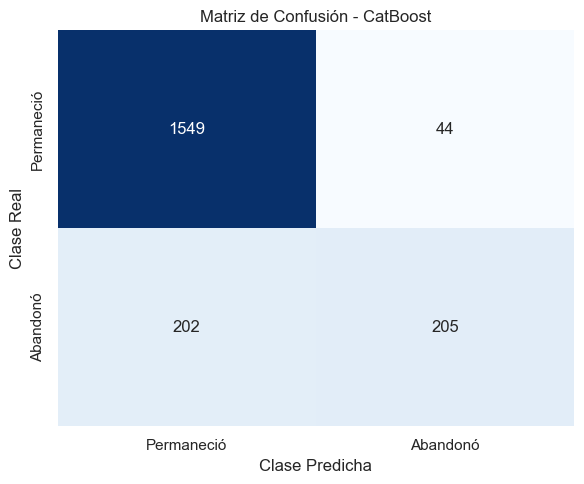

In [69]:
# Gráfico de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_catboost,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "CatBoost"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 12.6 Comparación Inicial de Modelos

Se compararán los resultados obtenidos por:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.
- LightGBM.
- CatBoost.

La métrica principal continuará siendo PR-AUC.

También se analizarán Recall, Precision, F1-Score y ROC-AUC para evaluar el comportamiento general de los modelos.

In [70]:
# Modelos incluidos en la comparación

modelos_comparacion_catboost = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial",

    "LightGBM",

    "CatBoost"

]

# Construcción de tabla

tabla_comparacion_catboost = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_comparacion_catboost

    ]

)

# Selección de columnas

tabla_comparacion_catboost = (

    tabla_comparacion_catboost[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

# Redondeo

columnas_metricas = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

tabla_comparacion_catboost[

    columnas_metricas

] = (

    tabla_comparacion_catboost[

        columnas_metricas

    ]

    .round(4)

)

tabla_comparacion_catboost

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48
1,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71
2,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72
3,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70
4,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73


##### 12.7 Diferencias Respecto de los Modelos Anteriores

Se calcularán las diferencias entre CatBoost y:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.
- LightGBM.

Los valores positivos representarán una mejora de CatBoost.

Los valores negativos representarán una disminución respecto del modelo utilizado como referencia.

In [71]:
# Métricas utilizadas

metricas_diferencia = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

# Construcción de tabla

comparacion_diferencias_cat = (
    pd.DataFrame({

        "Métrica": (
            metricas_diferencia
        ),

        "CatBoost": [

            resultado_catboost[
                "metricas_test"
            ][metrica]

            for metrica
            in metricas_diferencia

        ],

        "Diferencia CAT - Baseline": [

            (
                resultado_catboost[
                    "metricas_test"
                ][metrica]

                -

                resultado_logistico[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia CAT - RF": [

            (
                resultado_catboost[
                    "metricas_test"
                ][metrica]

                -

                resultado_random_forest[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia CAT - XGB": [

            (
                resultado_catboost[
                    "metricas_test"
                ][metrica]

                -

                resultado_xgboost_inicial[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ],

        "Diferencia CAT - LGBM": [

            (
                resultado_catboost[
                    "metricas_test"
                ][metrica]

                -

                resultado_lightgbm[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia

        ]

    })
)

# Redondeo

columnas_numericas_cat = (

    comparacion_diferencias_cat

    .select_dtypes(
        include="number"
    )

    .columns

)

comparacion_diferencias_cat[

    columnas_numericas_cat

] = (

    comparacion_diferencias_cat[

        columnas_numericas_cat

    ]

    .round(4)

)

comparacion_diferencias_cat

,Métrica,CatBoost,Diferencia CAT - Baseline,Diferencia CAT - RF,Diferencia CAT - XGB,Diferencia CAT - LGBM
0,Accuracy,0.88,0.07,0.01,0.01,0.02
1,Precision,0.82,0.23,0.01,0.04,0.08
2,Recall,0.50,0.32,0.06,0.01,0.01
3,F1-Score,0.62,0.34,0.05,0.02,0.03
4,ROC-AUC,0.87,0.09,0.00,0.00,0.01
5,PR-AUC (AP),0.73,0.25,0.02,0.01,0.03


##### 12.8 Estabilidad entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida mediante validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba.

Una diferencia pequeña indicará que el comportamiento del modelo se mantiene estable frente a datos no utilizados durante el entrenamiento.

In [72]:
# Comparación de estabilidad

tabla_estabilidad_cat = pd.DataFrame({

    "Modelo": [

        "CatBoost"

    ],

    "PR-AUC media CV": [

        resultado_catboost[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_catboost[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_catboost[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

# Diferencia

tabla_estabilidad_cat[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_cat[

        "PR-AUC prueba"

    ]

    -

    tabla_estabilidad_cat[

        "PR-AUC media CV"

    ]

)

# Redondeo

columnas_estabilidad_cat = (

    tabla_estabilidad_cat

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_cat[

    columnas_estabilidad_cat

] = (

    tabla_estabilidad_cat[

        columnas_estabilidad_cat

    ]

    .round(4)

)

tabla_estabilidad_cat

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,CatBoost,0.70,0.02,0.73,0.03


**Interpretación de CatBoost**

CatBoost presentó el mejor rendimiento general entre los modelos evaluados hasta el momento.

En el conjunto de prueba obtuvo:

- Accuracy: 0,88.
- Precision: 0,82.
- Recall: 0,50.
- F1-Score: 0,62.
- ROC-AUC: 0,87.
- PR-AUC: 0,73.

La **PR-AUC** aumentó desde 0,48 en la Regresión Logística hasta 0,73 en CatBoost. Este resultado representa la mejor capacidad obtenida hasta el momento para identificar y priorizar clientes con riesgo de abandono dentro de un problema con clases desbalanceadas.

También se observó una mejora importante en **Recall**. La Regresión Logística detectaba aproximadamente el 19% de los clientes que abandonaron, mientras que CatBoost identificó aproximadamente el 50%.

La **Matriz de Confusión** mostró:

- 1.549 verdaderos negativos.
- 44 falsos positivos.
- 202 falsos negativos.
- 205 verdaderos positivos.

Respecto de la **Regresión Logística**, CatBoost identificó correctamente 129 clientes adicionales que abandonaron y redujo los falsos negativos de 331 a 202.

Además, los falsos positivos disminuyeron de 53 a 44. Por lo tanto, la mejora en la detección no produjo un aumento de las alertas incorrectas.

Al compararlo con **Random Forest**, CatBoost mantuvo una Precision similar y presentó valores superiores de Recall, F1-Score, ROC-AUC y PR-AUC. Detectó 24 clientes adicionales que abandonaron y generó solamente tres falsos positivos adicionales.

Respecto de **XGBoost inicial**, CatBoost presentó una mejora leve pero consistente. Obtuvo valores superiores de Accuracy, Precision, Recall, F1-Score y PR-AUC. También redujo los falsos positivos de 56 a 44 y los falsos negativos de 208 a 202.

**CatBoost** superó a LightGBM en todas las métricas evaluadas. Además, redujo los falsos positivos de 71 a 44 y detectó cuatro clientes adicionales que abandonaron.

Los resultados de **Validación Cruzada** fueron consistentes con la evaluación sobre el conjunto de prueba. La PR-AUC promedio fue de 0,70, con un desvío de 0,02, mientras que en prueba alcanzó 0,73.

La diferencia entre **Validación y Prueba** fue reducida y no se observaron señales evidentes de inestabilidad. Sin embargo, la selección final no se realizará únicamente con el resultado del conjunto de prueba, sino considerando también el desempeño promedio obtenido mediante validación cruzada.

CatBoost constituye actualmente el modelo con mejor PR-AUC y mejor equilibrio general entre Precision y Recall. Luego de analizar los Modelos restantes, se evaluará si sigue siendo el mejor modelo.

#### 13. XGBoost Optimizado con Grid Search

La consigna solicita aplicar optimización de hiperparámetros únicamente al modelo XGBoost utilizando Grid Search.

Grid Search es una técnica de búsqueda exhaustiva que prueba diferentes combinaciones de hiperparámetros previamente definidos. Cada combinación se evalúa mediante validación cruzada y se selecciona aquella que obtiene el mejor resultado según una métrica determinada.

En este caso, la métrica principal será `average_precision`, interpretada como PR-AUC (Average Precision), debido a que el problema presenta clases desbalanceadas y el objetivo principal es identificar correctamente a los clientes con mayor riesgo de abandono.

La búsqueda se realizará únicamente sobre el conjunto de entrenamiento. El conjunto de prueba permanecerá separado y será utilizado únicamente para la evaluación final del mejor modelo encontrado.

##### 13.1 Hiperparámetros a Optimizar

Se optimizarán algunos hiperparámetros principales de XGBoost:

- `n_estimators`: cantidad de árboles construidos.
- `learning_rate`: contribución de cada árbol al modelo final.
- `max_depth`: profundidad máxima de cada árbol.
- `subsample`: proporción de observaciones utilizadas por árbol.
- `colsample_bytree`: proporción de variables utilizadas por árbol.
- `reg_lambda`: regularización L2.

La grilla será acotada para mantener un costo computacional razonable.

In [73]:
# Herramienta para optimización mediante búsqueda exhaustiva

from sklearn.model_selection import (
    GridSearchCV
)

print(
    "GridSearchCV importado correctamente."
)

GridSearchCV importado correctamente.


##### 13.2 Modelo Base para Grid Search

Se creará un nuevo modelo XGBoost base para la optimización.

Este modelo tendrá algunos parámetros fijos y otros serán ajustados mediante Grid Search.

Los parámetros fijos serán:

- `objective="binary:logistic"` para clasificación binaria.
- `eval_metric="logloss"` como métrica interna de entrenamiento.
- `importance_type="gain"` para luego analizar la importancia de variables.
- `random_state=42` para reproducibilidad.

In [74]:
# Modelo base de XGBoost para Grid Search

modelo_xgboost_grid = XGBClassifier(

    objective="binary:logistic",

    eval_metric="logloss",

    importance_type="gain",

    random_state=RANDOM_STATE,

    n_jobs=1,

    verbosity=0

)

print(
    "Modelo base de XGBoost "
    "para Grid Search creado correctamente."
)

Modelo base de XGBoost para Grid Search creado correctamente.


##### 13.3 Pipeline para Grid Search

El Pipeline incluirá:

1. El preprocesamiento común utilizado en los modelos anteriores.
2. El modelo XGBoost.

Grid Search evaluará distintas combinaciones de hiperparámetros del modelo, manteniendo siempre el mismo preprocesamiento.

Como el preprocesador se encuentra dentro del Pipeline, las transformaciones se ajustarán correctamente dentro de cada pliegue de validación cruzada.

In [75]:
# Pipeline de XGBoost para Grid Search

pipeline_xgboost_grid = Pipeline(

    steps=[

        (
            "preprocesamiento",
            preprocesador
        ),

        (
            "modelo",
            modelo_xgboost_grid
        )

    ]

)

print(
    "Pipeline de XGBoost para "
    "Grid Search creado correctamente."
)

Pipeline de XGBoost para Grid Search creado correctamente.


##### 13.4 Definición de la Grilla de Hiperparámetros

La grilla define los valores que Grid Search probará para cada hiperparámetro.

En este caso, se utilizará una grilla acotada:

- Dos valores para `n_estimators`.
- Dos valores para `learning_rate`.
- Dos valores para `max_depth`.
- Dos valores para `subsample`.
- Un valor para `colsample_bytree`.
- Dos valores para `reg_lambda`.

Esto genera un total de:

2 × 2 × 2 × 2 × 1 × 2 = 32 combinaciones.

Como se utilizará validación cruzada con cinco pliegues, se entrenarán:

32 × 5 = 160 modelos durante la búsqueda.

In [76]:
# Grilla de hiperparámetros para XGBoost

param_grid_xgboost = {

    "modelo__n_estimators": [

        200,

        300

    ],

    "modelo__learning_rate": [

        0.03,

        0.05

    ],

    "modelo__max_depth": [

        3,

        4

    ],

    "modelo__subsample": [

        0.80,

        1.00

    ],

    "modelo__colsample_bytree": [

        0.80

    ],

    "modelo__reg_lambda": [

        1,

        3

    ]

}

# Cantidad total de combinaciones

cantidad_combinaciones = 1

for valores in param_grid_xgboost.values():

    cantidad_combinaciones *= len(
        valores
    )

print(
    f"Cantidad de combinaciones "
    f"a evaluar: {cantidad_combinaciones}"
)

print(
    f"Cantidad estimada de entrenamientos "
    f"con {N_SPLITS} pliegues: "
    f"{cantidad_combinaciones * N_SPLITS}"
)

Cantidad de combinaciones a evaluar: 32
Cantidad estimada de entrenamientos con 5 pliegues: 160


##### 13.5 Configuración del Grid Search

El Grid Search se configurará de la siguiente manera:

- `estimator`: Pipeline de XGBoost.
- `param_grid`: grilla de hiperparámetros definida.
- `scoring="average_precision"`: métrica principal equivalente a PR-AUC (AP).
- `cv`: validación cruzada estratificada.
- `n_jobs=-1`: uso de procesamiento paralelo.
- `refit=True`: reentrena automáticamente el mejor modelo con todo el conjunto de entrenamiento.
- `verbose=1`: muestra el progreso de la búsqueda.

La métrica de optimización será PR-AUC (Average Precision), porque permite evaluar mejor el desempeño del modelo sobre la clase positiva en un contexto de desbalance.

In [77]:
# Configuración del Grid Search

grid_search_xgboost = GridSearchCV(

    estimator=(
        pipeline_xgboost_grid
    ),

    param_grid=(
        param_grid_xgboost
    ),

    scoring=(
        "average_precision"
    ),

    cv=(
        cv_estratificada
    ),

    n_jobs=-1,

    refit=True,

    verbose=1,

    return_train_score=True

)

print(
    "Grid Search configurado correctamente."
)

Grid Search configurado correctamente.


##### 13.6 Ejecución del Grid Search

A continuación se ejecutará la búsqueda de hiperparámetros.

Este proceso puede tardar varios minutos, ya que se entrenarán múltiples combinaciones de XGBoost mediante validación cruzada.

El conjunto de prueba no será utilizado durante esta etapa.

In [78]:
# Ejecución del Grid Search sobre el conjunto de entrenamiento

grid_search_xgboost.fit(

    X_train,

    y_train

)

print(
    "Grid Search finalizado correctamente."
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Grid Search finalizado correctamente.


##### 13.7 Mejores Hiperparámetros Encontrados

Una vez finalizado el Grid Search, se recuperarán:

- La mejor combinación de hiperparámetros.
- La mejor PR-AUC promedio obtenida durante la validación cruzada.

In [79]:
# Mejores hiperparámetros

print(
    "Mejores hiperparámetros encontrados:"
)

for parametro, valor in (
    grid_search_xgboost
    .best_params_
    .items()
):

    print(
        f"- {parametro}: {valor}"
    )

print(
    "\nMejor PR-AUC promedio "
    "en validación cruzada:"
)

print(
    round(
        grid_search_xgboost
        .best_score_,
        4
    )
)

Mejores hiperparámetros encontrados:
- modelo__colsample_bytree: 0.8
- modelo__learning_rate: 0.05
- modelo__max_depth: 3
- modelo__n_estimators: 300
- modelo__reg_lambda: 1
- modelo__subsample: 0.8

Mejor PR-AUC promedio en validación cruzada:
0.7031


In [80]:
# Tabla con los mejores resultados del Grid Search

resultados_grid_xgboost = pd.DataFrame(
    grid_search_xgboost.cv_results_
)

# Selección de columnas relevantes

columnas_grid = [

    "rank_test_score",

    "mean_test_score",

    "std_test_score",

    "mean_train_score",

    "std_train_score",

    "param_modelo__n_estimators",

    "param_modelo__learning_rate",

    "param_modelo__max_depth",

    "param_modelo__subsample",

    "param_modelo__colsample_bytree",

    "param_modelo__reg_lambda"

]

tabla_grid_xgboost = (

    resultados_grid_xgboost[
        columnas_grid
    ]

    .sort_values(
        by="rank_test_score"
    )

    .head(10)

    .copy()

)

# Redondeo de métricas

columnas_score_grid = [

    "mean_test_score",

    "std_test_score",

    "mean_train_score",

    "std_train_score"

]

tabla_grid_xgboost[

    columnas_score_grid

] = (

    tabla_grid_xgboost[

        columnas_score_grid

    ]

    .round(4)

)

tabla_grid_xgboost

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,param_modelo__n_estimators,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__reg_lambda
20,1,0.70,0.02,0.77,0.00,300,0.05,3,0.80,0.80,1
24,2,0.70,0.02,0.79,0.01,200,0.05,4,0.80,0.80,1
22,3,0.70,0.02,0.76,0.01,300,0.05,3,0.80,0.80,3
4,4,0.70,0.02,0.75,0.01,300,0.03,3,0.80,0.80,1
28,5,0.70,0.02,0.82,0.01,300,0.05,4,0.80,0.80,1
16,6,0.70,0.02,0.75,0.00,200,0.05,3,0.80,0.80,1
21,7,0.70,0.02,0.76,0.01,300,0.05,3,1.00,0.80,1
26,8,0.70,0.02,0.78,0.01,200,0.05,4,0.80,0.80,3
30,9,0.70,0.02,0.81,0.01,300,0.05,4,0.80,0.80,3
12,10,0.70,0.02,0.78,0.01,300,0.03,4,0.80,0.80,1


##### 13.8 Evaluación del XGBoost Optimizado

Grid Search devuelve automáticamente el mejor Pipeline encontrado en el atributo `best_estimator_`.

Ese Pipeline ya fue reentrenado utilizando todo el conjunto de entrenamiento debido a que se configuró `refit=True`.

Ahora, se utilizará la función común de evaluación para calcular nuevamente:

- Validación cruzada.
- Métricas sobre el conjunto de prueba.
- Matriz de confusión.

Esto permitirá comparar el XGBoost optimizado con el XGBoost inicial y con los demás modelos.

In [81]:
# Recuperación del mejor modelo encontrado por Grid Search

pipeline_xgboost_optimizado = (
    grid_search_xgboost
    .best_estimator_
)

print(
    "Mejor Pipeline de XGBoost "
    "recuperado correctamente."
)

Mejor Pipeline de XGBoost recuperado correctamente.


In [82]:
# Evaluación del XGBoost optimizado

resultado_xgboost_optimizado = evaluar_modelo(

    nombre_modelo=(
        "XGBoost optimizado"
    ),

    pipeline_modelo=(
        pipeline_xgboost_optimizado
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "XGBoost optimizado "
    "evaluado correctamente."
)

XGBoost optimizado evaluado correctamente.


In [83]:
# Almacenamiento de resultados

resultados_modelos[

    "XGBoost optimizado"

] = resultado_xgboost_optimizado

print(
    "Resultados de XGBoost optimizado "
    "almacenados correctamente."
)

Resultados de XGBoost optimizado almacenados correctamente.


In [84]:
# Visualización de resultados

mostrar_resultados(

    resultado_xgboost_optimizado

)

MODELO: XGBoost optimizado

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.77,0.01
2,Recall,0.48,0.02
3,F1-Score,0.59,0.02
4,ROC-AUC,0.87,0.01
5,PR-AUC (AP),0.70,0.02



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,XGBoost optimizado,0.87,0.79,0.50,0.61,0.87,0.72,0.70,0.02


##### 13.9 Matriz de Confusión del XGBoost Optimizado

Se analizará la matriz de confusión del XGBoost optimizado para observar si la optimización permitió mejorar la detección de clientes que abandonaron respecto del XGBoost inicial.

In [85]:
# Recuperación de la Matriz de Confusión

matriz_xgboost_optimizado = (

    resultado_xgboost_optimizado[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_xgb_opt, fp_xgb_opt, fn_xgb_opt, tp_xgb_opt = (

    matriz_xgboost_optimizado
    .ravel()

)

# Creación de tabla

tabla_matriz_xgboost_optimizado = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_xgb_opt,

            fp_xgb_opt,

            fn_xgb_opt,

            tp_xgb_opt

        ]

    })
)

tabla_matriz_xgboost_optimizado

,Resultado,Cantidad
0,Verdaderos negativos,1539
1,Falsos positivos,54
2,Falsos negativos,205
3,Verdaderos positivos,202


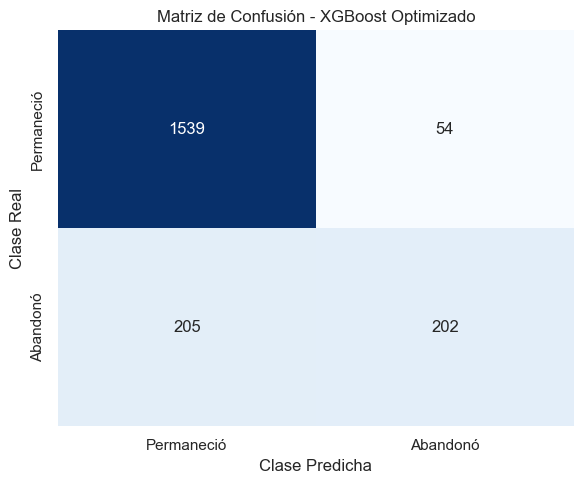

In [86]:
# Gráfico de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_xgboost_optimizado,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "XGBoost Optimizado"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 13.10 Comparación entre XGBoost Inicial y XGBoost Optimizado

Se compararán las métricas obtenidas por XGBoost antes y después de la optimización mediante Grid Search.

Esta comparación permitirá evaluar si el ajuste de hiperparámetros produjo una mejora real en el desempeño del modelo.

In [87]:
# Comparación entre XGBoost inicial y XGBoost optimizado

modelos_xgboost_comparacion = [

    "XGBoost inicial",

    "XGBoost optimizado"

]

tabla_comparacion_xgboost = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_xgboost_comparacion

    ]

)

tabla_comparacion_xgboost = (

    tabla_comparacion_xgboost[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

tabla_comparacion_xgboost[

    columnas_metricas

] = (

    tabla_comparacion_xgboost[

        columnas_metricas

    ]

    .round(4)

)

tabla_comparacion_xgboost

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72
1,XGBoost optimizado,0.87,0.79,0.50,0.61,0.87,0.72


In [88]:
# Diferencias entre XGBoost optimizado y XGBoost inicial

comparacion_xgb_opt_vs_inicial = pd.DataFrame({

    "Métrica": (
        metricas_diferencia
    ),

    "XGBoost inicial": [

        resultado_xgboost_inicial[
            "metricas_test"
        ][metrica]

        for metrica
        in metricas_diferencia

    ],

    "XGBoost optimizado": [

        resultado_xgboost_optimizado[
            "metricas_test"
        ][metrica]

        for metrica
        in metricas_diferencia

    ]

})

comparacion_xgb_opt_vs_inicial[

    "Diferencia optimizado - inicial"

] = (

    comparacion_xgb_opt_vs_inicial[

        "XGBoost optimizado"

    ]

    -

    comparacion_xgb_opt_vs_inicial[

        "XGBoost inicial"

    ]

)

columnas_num_xgb_opt = (

    comparacion_xgb_opt_vs_inicial

    .select_dtypes(
        include="number"
    )

    .columns

)

comparacion_xgb_opt_vs_inicial[

    columnas_num_xgb_opt

] = (

    comparacion_xgb_opt_vs_inicial[

        columnas_num_xgb_opt

    ]

    .round(4)

)

comparacion_xgb_opt_vs_inicial

,Métrica,XGBoost inicial,XGBoost optimizado,Diferencia optimizado - inicial
0,Accuracy,0.87,0.87,0.00
1,Precision,0.78,0.79,0.01
2,Recall,0.49,0.50,0.01
3,F1-Score,0.60,0.61,0.01
4,ROC-AUC,0.87,0.87,0.00
5,PR-AUC (AP),0.72,0.72,0.00


##### 13.11 Comparación con Todos los Modelos Evaluados

Se incorporará XGBoost optimizado a la tabla comparativa general.

Esto permitirá analizar si el modelo optimizado supera a Regresión Logística, Random Forest, XGBoost inicial, LightGBM y CatBoost.

In [89]:
# Modelos evaluados hasta este punto

modelos_comparacion_xgb_opt = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial",

    "LightGBM",

    "CatBoost",

    "XGBoost optimizado"

]

tabla_comparacion_xgb_opt = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_comparacion_xgb_opt

    ]

)

tabla_comparacion_xgb_opt = (

    tabla_comparacion_xgb_opt[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

tabla_comparacion_xgb_opt[

    columnas_metricas

] = (

    tabla_comparacion_xgb_opt[

        columnas_metricas

    ]

    .round(4)

)

tabla_comparacion_xgb_opt.sort_values(

    by="PR-AUC (AP)",

    ascending=False

)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
4,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73
5,XGBoost optimizado,0.87,0.79,0.50,0.61,0.87,0.72
2,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72
1,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71
3,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70
0,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48


##### 13.12 Estabilidad entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida mediante validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba para el XGBoost optimizado.

In [90]:
# Comparación de estabilidad

tabla_estabilidad_xgb_opt = pd.DataFrame({

    "Modelo": [

        "XGBoost optimizado"

    ],

    "PR-AUC media CV": [

        resultado_xgboost_optimizado[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_xgboost_optimizado[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_xgboost_optimizado[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

tabla_estabilidad_xgb_opt[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_xgb_opt[

        "PR-AUC prueba"

    ]

    -

    tabla_estabilidad_xgb_opt[

        "PR-AUC media CV"

    ]

)

columnas_estabilidad_xgb_opt = (

    tabla_estabilidad_xgb_opt

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_xgb_opt[

    columnas_estabilidad_xgb_opt

] = (

    tabla_estabilidad_xgb_opt[

        columnas_estabilidad_xgb_opt

    ]

    .round(4)

)

tabla_estabilidad_xgb_opt

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,XGBoost optimizado,0.70,0.02,0.72,0.02


##### 13.13 Nota sobre Optuna

**Optuna** es una herramienta moderna de optimización bayesiana que permite buscar hiperparámetros de manera más eficiente que una grilla exhaustiva.

A diferencia de *Grid Search*, que prueba todas las combinaciones definidas manualmente, Optuna utiliza los resultados de pruebas anteriores para explorar regiones prometedoras del espacio de hiperparámetros.

La consigna indica que Optuna es opcional y que, en caso de implementarse, deberían utilizarse 50 trials.

En este notebook no se implementó Optuna, ya que el requisito obligatorio del Avance 2 es optimizar XGBoost mediante Grid Search.

**Interpretación del XGBoost Optimizado**

Grid Search evaluó 32 combinaciones de hiperparámetros mediante validación cruzada estratificada con cinco pliegues.

La mejor configuración encontrada fue:

- `n_estimators=300`.
- `learning_rate=0.05`.
- `max_depth=3`.
- `subsample=0.80`.
- `colsample_bytree=0.80`.
- `reg_lambda=1`.

La mejor **PR-AUC** promedio obtenida durante la búsqueda fue de 0,7031.

La configuración seleccionada fue muy similar a la utilizada en el XGBoost inicial. La principal diferencia fue la reducción de `max_depth` desde 4 hasta 3.

Esto indica que, dentro de la grilla evaluada, un modelo con árboles ligeramente menos profundos alcanzó el mejor desempeño promedio de validación.

En el conjunto de prueba, XGBoost optimizado obtuvo:

- Accuracy: 0,87.
- Precision: 0,79.
- Recall: 0,50.
- F1-Score: 0,61.
- ROC-AUC: 0,87.
- PR-AUC: 0,72.

La **Matriz de Confusión** mostró:

- 1.539 verdaderos negativos.
- 54 falsos positivos.
- 205 falsos negativos.
- 202 verdaderos positivos.

Respecto de XGBoost inicial, el modelo optimizado identificó correctamente tres clientes adicionales que abandonaron y *redujo los falsos negativos* de 208 a 205.

También *redujo los falsos positivos* de 56 a 54.

La optimización generó **mejoras pequeñas** en *Precision, Recall y F1-Score*. Sin embargo, Accuracy, ROC-AUC y PR-AUC se mantuvieron prácticamente sin cambios.

La ausencia de una mejora importante en PR-AUC no significa que Grid Search haya fallado. La búsqueda mostró que la configuración inicial ya se encontraba cerca del mejor resultado posible dentro del espacio de hiperparámetros evaluado.

Los resultados de **Validación Cruzada** fueron consistentes con la evaluación sobre el conjunto de prueba. La PR-AUC promedio fue de 0,70, con un desvío de 0,02, mientras que en prueba alcanzó 0,72.

La pequeña diferencia entre validación y prueba sugiere que el modelo mantiene un comportamiento estable y no presenta señales evidentes de pérdida de generalización.

XGBoost optimizado constituye una mejora leve respecto del modelo inicial. Sin embargo, **CatBoost mantiene hasta el momento la mejor PR-AUC**, con un valor de 0,73.

La selección definitiva deberá realizarse después de evaluar el modelo Stacking.

#### 14. Stacking

Stacking es una técnica de ensamble que combina las predicciones generadas por diferentes modelos.

A diferencia de un sistema de votación simple, Stacking utiliza un modelo adicional denominado meta-modelo o meta-learner.

El procedimiento se divide en dos niveles:

**Nivel 1: modelos base**

- XGBoost optimizado.
- LightGBM.
- CatBoost.

Cada modelo genera probabilidades de abandono utilizando patrones y estrategias de aprendizaje diferentes.

**Nivel 2: meta-modelo**

- Regresión Logística regularizada.

El meta-modelo utiliza las predicciones generadas por los modelos base y aprende cómo combinarlas para producir la clasificación final.

La generación de predicciones para entrenar el meta-modelo se realizará mediante validación cruzada. De esta manera, se evita que la Regresión Logística aprenda utilizando predicciones obtenidas sobre los mismos registros empleados para entrenar los modelos base.

In [91]:
# Importar herramientas para construir el modelo Stacking

from sklearn.ensemble import (
    StackingClassifier
)

from sklearn.base import (
    clone
)

print(
    "Herramientas para Stacking "
    "importadas correctamente."
)

Herramientas para Stacking importadas correctamente.


##### 14.1 Validación Cruzada Interna del Stacking

Stacking utilizará validación cruzada estratificada con cinco pliegues para generar las predicciones que recibirá el meta-modelo.

En cada iteración:

1. Los modelos base se entrenan utilizando cuatro pliegues.
2. Generan predicciones sobre el pliegue restante.
3. El proceso se repite hasta obtener predicciones para todos los registros.
4. Las predicciones obtenidas se utilizan para entrenar la Regresión Logística.

Este procedimiento evita que el meta-modelo sea entrenado con predicciones generadas sobre observaciones que los modelos base ya utilizaron durante su propio entrenamiento.

In [92]:
# Validación cruzada interna utilizada por Stacking

cv_stacking = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=RANDOM_STATE

)

print(
    "Validación cruzada interna "
    "de Stacking configurada correctamente."
)

Validación cruzada interna de Stacking configurada correctamente.


##### 14.2 Definición de los Modelos Base

Los modelos de nivel 1 serán:

- XGBoost optimizado mediante Grid Search.
- LightGBM.
- CatBoost.

Se utilizarán copias nuevas de los modelos mediante `clone`.

Esta función conserva la configuración y los hiperparámetros, pero elimina cualquier ajuste previo. De esta manera, Stacking podrá entrenar cada modelo nuevamente dentro de su propio procedimiento de validación cruzada.

In [93]:
# Modelos base utilizados en el primer nivel del Stacking

estimadores_base = [

    (
        "xgboost",

        clone(
            pipeline_xgboost_optimizado
        )
    ),

    (
        "lightgbm",

        clone(
            pipeline_lightgbm
        )
    ),

    (
        "catboost",

        clone(
            pipeline_catboost
        )
    )

]

print(
    "Modelos base definidos correctamente."
)

print(
    "\nModelos incluidos:"
)

for nombre, modelo in estimadores_base:

    print(
        f"- {nombre}"
    )

Modelos base definidos correctamente.

Modelos incluidos:
- xgboost
- lightgbm
- catboost


##### 14.3 Definición del Meta-Modelo

La Regresión Logística será utilizada como meta-modelo.

Se aplicará regularización L2 mediante:

- `penalty="l2"`.
- `C=1.0`.

La regularización ayuda a controlar el tamaño de los coeficientes y reduce el riesgo de que el meta-modelo dependa excesivamente de las predicciones de un único algoritmo.

La Regresión Logística no recibirá directamente las variables originales. Utilizará las probabilidades generadas por XGBoost, LightGBM y CatBoost.

In [94]:
# Meta-modelo del Stacking

meta_modelo_logistico = (
    LogisticRegression(

        l1_ratio=0.0,

        C=1.0,

        solver="lbfgs",

        max_iter=1000

    )
)

print(
    "Meta-modelo de Regresión Logística "
    "creado correctamente."
)

Meta-modelo de Regresión Logística creado correctamente.


##### 14.4 Construcción del Modelo Stacking

El modelo Stacking utilizará:

- XGBoost optimizado.
- LightGBM.
- CatBoost.

Las probabilidades generadas por los modelos base serán utilizadas como variables de entrada para la Regresión Logística regularizada.

Se utilizará:

- `stack_method="predict_proba"` para trabajar con probabilidades.
- `passthrough=False` para que el meta-modelo utilice únicamente las predicciones de los modelos base.
- Validación cruzada estratificada con cinco pliegues.

No se incorporarán las variables originales directamente al meta-modelo, debido a que la estructura solicitada se centra en combinar las predicciones de los algoritmos de Gradient Boosting.

In [95]:
# Construcción del modelo Stacking

modelo_stacking = StackingClassifier(

    estimators=(
        estimadores_base
    ),

    final_estimator=(
        meta_modelo_logistico
    ),

    cv=(
        cv_stacking
    ),

    stack_method=(
        "predict_proba"
    ),

    passthrough=False,

    n_jobs=1

)

print(
    "Modelo Stacking "
    "creado correctamente."
)

Modelo Stacking creado correctamente.


##### 14.5 Entrenamiento y Evaluación

Stacking será evaluado mediante el mismo protocolo aplicado a los modelos anteriores.

La evaluación utilizará:

- Validación cruzada estratificada.
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

El procedimiento incorpora dos niveles de validación:

1. Validación cruzada interna, utilizada por Stacking para generar las predicciones que entrenan al meta-modelo.
2. Validación cruzada externa, utilizada para evaluar el rendimiento general del ensamble.

Posteriormente, el modelo será entrenado utilizando los 8.000 registros del conjunto de entrenamiento y evaluado sobre los 2.000 clientes reservados para prueba.

In [96]:
# Evaluación del modelo Stacking

resultado_stacking = evaluar_modelo(

    nombre_modelo=(
        "Stacking"
    ),

    pipeline_modelo=(
        modelo_stacking
    ),

    X_train=(
        X_train
    ),

    y_train=(
        y_train
    ),

    X_test=(
        X_test
    ),

    y_test=(
        y_test
    ),

    cv=(
        cv_estratificada
    ),

    scoring=(
        metricas_cv
    )

)

print(
    "Stacking "
    "evaluado correctamente."
)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X d

Stacking evaluado correctamente.


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [97]:
# Almacenamiento de resultados

resultados_modelos[

    "Stacking"

] = resultado_stacking

print(
    "Resultados de Stacking "
    "almacenados correctamente."
)

Resultados de Stacking almacenados correctamente.


In [98]:
# Visualización de resultados

mostrar_resultados(

    resultado_stacking

)

MODELO: Stacking

Resultados de validación cruzada:



,Métrica,Media CV,Desvío CV
0,Accuracy,0.86,0.01
1,Precision,0.75,0.03
2,Recall,0.48,0.03
3,F1-Score,0.59,0.03
4,ROC-AUC,0.87,0.01
5,PR-AUC (AP),0.71,0.02



Resultados sobre el conjunto de prueba:



,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,Stacking,0.87,0.79,0.50,0.61,0.87,0.73,0.71,0.02


##### 14.6 Matriz de Confusión

La matriz de confusión permitirá analizar el comportamiento final del Stacking.

Se observarán especialmente:

- Verdaderos positivos.
- Falsos negativos.
- Falsos positivos.
- Diferencias respecto de CatBoost y XGBoost optimizado.

El objetivo será determinar si la combinación de modelos mejora la detección de clientes que abandonaron y mantiene un equilibrio adecuado entre Recall y Precision

In [99]:
# Recuperación de la Matriz de Confusión

matriz_stacking = (

    resultado_stacking[

        "matriz_confusion"

    ]

)

# Extracción de componentes

tn_stack, fp_stack, fn_stack, tp_stack = (

    matriz_stacking
    .ravel()

)

# Creación de tabla

tabla_matriz_stacking = (
    pd.DataFrame({

        "Resultado": [

            "Verdaderos negativos",

            "Falsos positivos",

            "Falsos negativos",

            "Verdaderos positivos"

        ],

        "Cantidad": [

            tn_stack,

            fp_stack,

            fn_stack,

            tp_stack

        ]

    })
)

tabla_matriz_stacking

,Resultado,Cantidad
0,Verdaderos negativos,1540
1,Falsos positivos,53
2,Falsos negativos,203
3,Verdaderos positivos,204


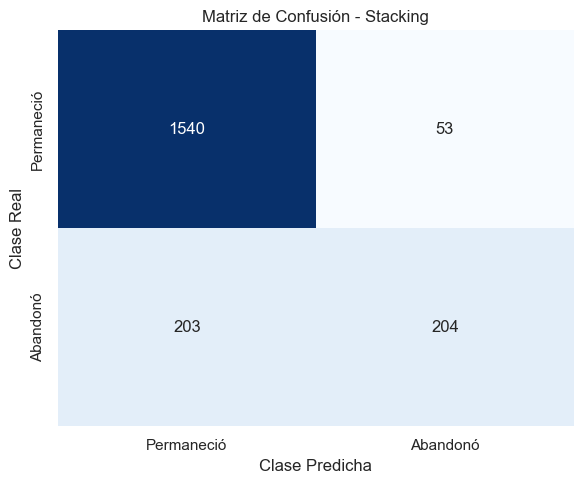

In [100]:
# Gráfico de la Matriz de Confusión

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(

    matriz_stacking,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    xticklabels=[

        "Permaneció",

        "Abandonó"

    ],

    yticklabels=[

        "Permaneció",

        "Abandonó"

    ]

)

plt.title(

    "Matriz de Confusión - "
    "Stacking"

)

plt.xlabel(

    "Clase Predicha"

)

plt.ylabel(

    "Clase Real"

)

plt.tight_layout()

plt.show()

##### 14.7 Comparación de todos los Modelos

Se incorporará Stacking a la tabla comparativa general.

Los modelos evaluados serán:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.
- LightGBM.
- CatBoost.
- XGBoost optimizado.
- Stacking.

La comparación priorizará PR-AUC y considerará también Accuracy, Precision, Recall, F1-Score y ROC-AUC.

In [101]:
# Modelos evaluados

modelos_comparacion_final = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial",

    "LightGBM",

    "CatBoost",

    "XGBoost optimizado",

    "Stacking"

]

# Construcción de tabla

tabla_comparacion_final = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_comparacion_final

    ]

)

# Selección de columnas

tabla_comparacion_final = (

    tabla_comparacion_final[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)"

        ]

    ]

)

# Redondeo

tabla_comparacion_final[

    columnas_metricas

] = (

    tabla_comparacion_final[

        columnas_metricas

    ]

    .round(4)

)

# Orden por métrica principal

tabla_comparacion_final = (

    tabla_comparacion_final

    .sort_values(

        by="PR-AUC (AP)",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)

tabla_comparacion_final

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73
1,Stacking,0.87,0.79,0.50,0.61,0.87,0.73
2,XGBoost optimizado,0.87,0.79,0.50,0.61,0.87,0.72
3,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72
4,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71
5,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70
6,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48


##### 14.8 Diferencias del Stacking respecto de los Modelos de Referencia

Stacking será comparado directamente con:

- Regresión Logística baseline.
- XGBoost optimizado.
- CatBoost.

CatBoost es actualmente el modelo individual con mejor PR-AUC.

La comparación permitirá determinar si el ensamble logra superar al mejor algoritmo individual

In [102]:
# Métricas utilizadas

metricas_diferencia_stacking = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]

# Comparación de diferencias

comparacion_diferencias_stacking = (
    pd.DataFrame({

        "Métrica": (
            metricas_diferencia_stacking
        ),

        "Stacking": [

            resultado_stacking[
                "metricas_test"
            ][metrica]

            for metrica
            in metricas_diferencia_stacking

        ],

        "Diferencia STACK - Baseline": [

            (
                resultado_stacking[
                    "metricas_test"
                ][metrica]

                -

                resultado_logistico[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia_stacking

        ],

        "Diferencia STACK - XGB Opt": [

            (
                resultado_stacking[
                    "metricas_test"
                ][metrica]

                -

                resultado_xgboost_optimizado[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia_stacking

        ],

        "Diferencia STACK - CatBoost": [

            (
                resultado_stacking[
                    "metricas_test"
                ][metrica]

                -

                resultado_catboost[
                    "metricas_test"
                ][metrica]
            )

            for metrica
            in metricas_diferencia_stacking

        ]

    })
)

# Redondeo

columnas_numericas_stack = (

    comparacion_diferencias_stacking

    .select_dtypes(
        include="number"
    )

    .columns

)

comparacion_diferencias_stacking[

    columnas_numericas_stack

] = (

    comparacion_diferencias_stacking[

        columnas_numericas_stack

    ]

    .round(4)

)

comparacion_diferencias_stacking

,Métrica,Stacking,Diferencia STACK - Baseline,Diferencia STACK - XGB Opt,Diferencia STACK - CatBoost
0,Accuracy,0.87,0.06,0.00,-0.01
1,Precision,0.79,0.20,0.00,-0.03
2,Recall,0.50,0.31,0.00,-0.00
3,F1-Score,0.61,0.33,0.01,-0.01
4,ROC-AUC,0.87,0.10,0.00,0.00
5,PR-AUC (AP),0.73,0.25,0.01,-0.00


##### 14.9 Estabilidad entre Validación Cruzada y Prueba

Se comparará la PR-AUC promedio obtenida mediante validación cruzada con la PR-AUC obtenida sobre el conjunto de prueba.

Esta comparación permitirá evaluar si el comportamiento del Stacking se mantiene estable frente a datos no utilizados durante el entrenamiento.

In [103]:
# Comparación de estabilidad

tabla_estabilidad_stacking = pd.DataFrame({

    "Modelo": [

        "Stacking"

    ],

    "PR-AUC media CV": [

        resultado_stacking[
            "metricas_test"
        ][
            "CV PR-AUC media"
        ]

    ],

    "Desvío PR-AUC CV": [

        resultado_stacking[
            "metricas_test"
        ][
            "CV PR-AUC desvío"
        ]

    ],

    "PR-AUC prueba": [

        resultado_stacking[
            "metricas_test"
        ][
            "PR-AUC (AP)"
        ]

    ]

})

# Diferencia

tabla_estabilidad_stacking[

    "Diferencia prueba - CV"

] = (

    tabla_estabilidad_stacking[

        "PR-AUC prueba"

    ]

    -

    tabla_estabilidad_stacking[

        "PR-AUC media CV"

    ]

)

# Redondeo

columnas_estabilidad_stacking = (

    tabla_estabilidad_stacking

    .select_dtypes(
        include="number"
    )

    .columns

)

tabla_estabilidad_stacking[

    columnas_estabilidad_stacking

] = (

    tabla_estabilidad_stacking[

        columnas_estabilidad_stacking

    ]

    .round(4)

)

tabla_estabilidad_stacking

,Modelo,PR-AUC media CV,Desvío PR-AUC CV,PR-AUC prueba,Diferencia prueba - CV
0,Stacking,0.71,0.02,0.73,0.02


**Interpretaciín de Stacking**

Stacking presentó un rendimiento muy superior a la Regresión Logística baseline y resultados competitivos respecto de los mejores modelos individuales.

En el conjunto de prueba obtuvo:

- Accuracy: 0,87.
- Precision: 0,79.
- Recall: 0,50.
- F1-Score: 0,61.
- ROC-AUC: 0,87.
- PR-AUC: 0,73.

La matriz de confusión mostró:

- 1.540 verdaderos negativos.
- 53 falsos positivos.
- 203 falsos negativos.
- 204 verdaderos positivos.

Respecto de la **Regresión Logística**, Stacking identificó correctamente 128 clientes adicionales que abandonaron y redujo los falsos negativos de 331 a 203.

La mejora se produjo sin aumentar los falsos positivos, que se mantuvieron en 53.

Al compararlo con **XGBoost optimizado**, Stacking presentó resultados muy similares. Obtuvo una mejora pequeña en PR-AUC y detectó dos clientes adicionales que abandonaron.

Sin embargo, Stacking no logró superar claramente a CatBoost.

Ambos modelos alcanzaron una **PR-AUC** de 0,73 al redondear. CatBoost obtuvo valores superiores de Accuracy, Precision y F1-Score.

Además, CatBoost generó 44 falsos positivos frente a los 53 obtenidos por Stacking y detectó un cliente adicional que abandonó.

Los resultados de validación cruzada fueron consistentes con la evaluación sobre prueba. La PR-AUC promedio fue de 0,71, con un desvío de 0,02, mientras que en el conjunto de prueba alcanzó 0,73.

La diferencia de 0,02 entre validación y prueba es reducida y no indica problemas evidentes de generalización.

Stacking logró combinar correctamente las predicciones de XGBoost, LightGBM y CatBoost mediante una Regresión Logística regularizada.

Sin embargo, la combinación no produjo una mejora importante frente al mejor modelo individual.

Esto puede deberse a que los tres modelos base pertenecen a la familia de Gradient Boosting y generan predicciones relativamente similares. Cuando los modelos presentan comportamientos similares, el meta-modelo dispone de menos información complementaria para producir una mejora adicional.

Por lo tanto, Stacking constituye un modelo competitivo y supera ampliamente al baseline, pero **CatBoost** continúa siendo la alternativa más favorable por su mejor equilibrio entre métricas y su menor complejidad.

#### 15. Comparación Visual de los Modelos

Luego de entrenar y evaluar todos los modelos obligatorios del Avance 2, se realizará una comparación consolidada.

Los modelos incluidos serán:

- Regresión Logística.
- Random Forest.
- XGBoost inicial.
- LightGBM.
- CatBoost.
- XGBoost optimizado.
- Stacking.

La comparación considerará:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

PR-AUC continuará siendo la métrica principal debido al desbalance existente en la variable objetivo.

In [104]:
# Orden original de los modelos evaluados

modelos_evaluados = [

    "Regresión Logística",

    "Random Forest",

    "XGBoost inicial",

    "LightGBM",

    "CatBoost",

    "XGBoost optimizado",

    "Stacking"

]


# Creación de la tabla
# utilizando los resultados completos

tabla_comparacion_visual = pd.DataFrame(

    [

        {

            "Modelo": nombre_modelo,

            "Accuracy": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "Accuracy"
                ]
            ),

            "Precision": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "Precision"
                ]
            ),

            "Recall": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "Recall"
                ]
            ),

            "F1-Score": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "F1-Score"
                ]
            ),

            "ROC-AUC": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "ROC-AUC"
                ]
            ),

            "PR-AUC (AP)": (
                resultados_modelos[
                    nombre_modelo
                ][
                    "metricas_test"
                ][
                    "PR-AUC (AP)"
                ]
            )

        }

        for nombre_modelo
        in modelos_evaluados

    ]

)


# Ranking utilizando los valores
# completos antes del redondeo

tabla_comparacion_visual[

    "Ranking PR-AUC"

] = (

    tabla_comparacion_visual[

        "PR-AUC (AP)"

    ]

    .rank(

        method="min",

        ascending=False

    )

    .astype(int)

)


# Ordenamiento por PR-AUC

tabla_comparacion_visual = (

    tabla_comparacion_visual

    .sort_values(

        by="PR-AUC (AP)",

        ascending=False

    )

    .reset_index(

        drop=True

    )

)


# Copia para visualización

tabla_comparacion_mostrar = (

    tabla_comparacion_visual

    .copy()

)


# Columnas numéricas

columnas_metricas_finales = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]


# Redondeo únicamente
# para mostrar la tabla

tabla_comparacion_mostrar[

    columnas_metricas_finales

] = (

    tabla_comparacion_mostrar[

        columnas_metricas_finales

    ]

    .round(4)

)


tabla_comparacion_mostrar

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),Ranking PR-AUC
0,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73,1
1,Stacking,0.87,0.79,0.50,0.61,0.87,0.73,2
2,XGBoost optimizado,0.87,0.79,0.50,0.61,0.87,0.72,3
3,XGBoost inicial,0.87,0.78,0.49,0.60,0.87,0.72,4
4,Random Forest,0.87,0.82,0.44,0.58,0.86,0.71,5
5,LightGBM,0.86,0.74,0.49,0.59,0.86,0.70,6
6,Regresión Logística,0.81,0.59,0.19,0.28,0.77,0.48,7


La tabla consolidada muestra que los modelos basados en árboles superaron ampliamente a la Regresión Logística baseline.

CatBoost y Stacking obtuvieron las mayores PR-AUC sobre el conjunto de prueba.

Sin embargo, CatBoost presentó un mejor equilibrio general:

- Mayor Accuracy.
- Mayor Precision.
- Mayor F1-Score.
- Una matriz de confusión ligeramente superior.
- Menor complejidad respecto de Stacking.

Por lo tanto, **CatBoost** se mantiene como el modelo seleccionado.

##### 15.1 Comparación de Métricas Basadas en el Umbral de Clasificación

Accuracy, Precision, Recall y F1-Score se calculan utilizando las clases predichas.

Estas métricas dependen del umbral de clasificación utilizado.

En este avance se mantuvo el umbral predeterminado de 0,5 para todos los modelos.

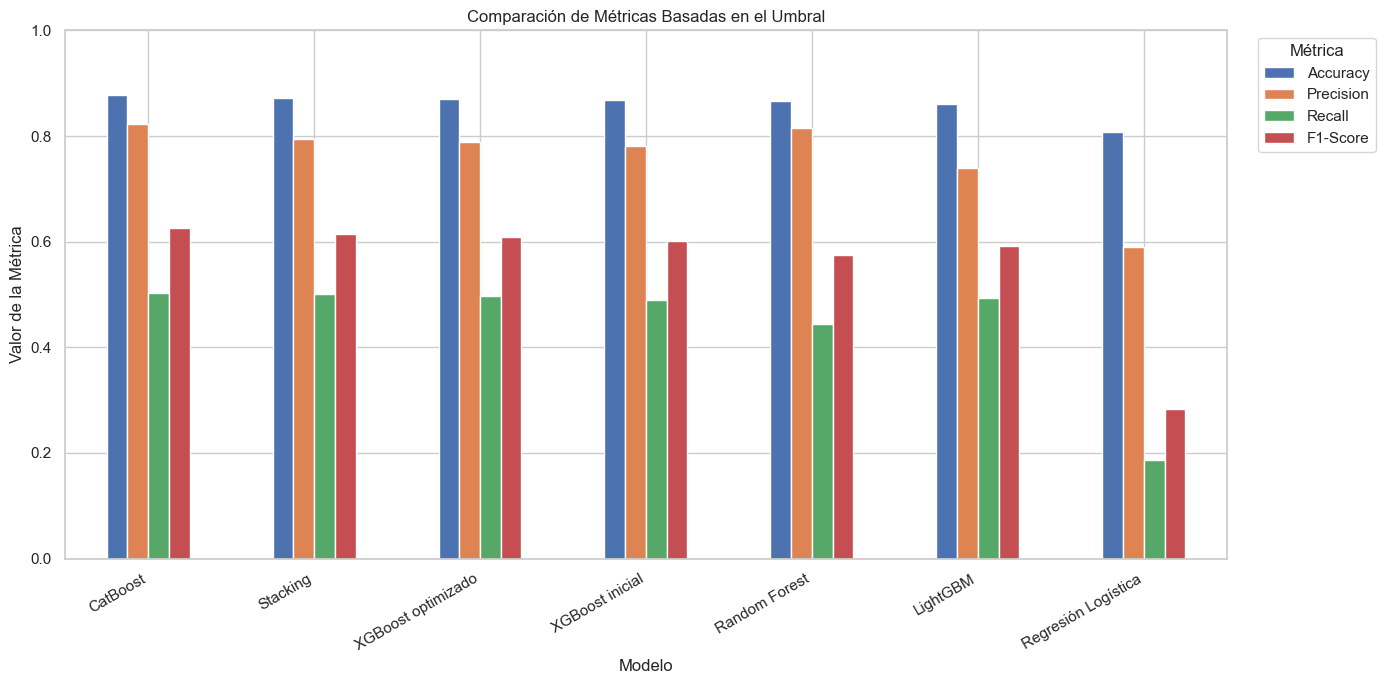

In [105]:
# Métricas dependientes del umbral de clasificación

metricas_umbral = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score"

]


# Preparación de la tabla

tabla_grafico_umbral = (

    tabla_comparacion_visual[

        [

            "Modelo"

        ]

        +

        metricas_umbral

    ]

    .set_index(

        "Modelo"

    )

)


# Gráfico comparativo

ax = tabla_grafico_umbral.plot(

    kind="bar",

    figsize=(14, 7)

)


ax.set_title(

    "Comparación de Métricas "
    "Basadas en el Umbral"

)

ax.set_xlabel(

    "Modelo"

)

ax.set_ylabel(

    "Valor de la Métrica"

)

ax.set_ylim(

    0,

    1

)

plt.xticks(

    rotation=30,

    ha="right"

)

plt.legend(

    title="Métrica",

    bbox_to_anchor=(

        1.02,

        1

    ),

    loc="upper left"

)

plt.tight_layout()

plt.show()

Los modelos complejos superaron claramente a la Regresión Logística en Recall y F1-Score.

La mayor diferencia se observa en la detección de clientes que abandonaron.

La Regresión Logística presentó un Recall cercano a 0,19, mientras que CatBoost, XGBoost optimizado y Stacking alcanzaron valores cercanos a 0,50.

CatBoost mostró uno de los mejores equilibrios entre Precision y Recall, alcanzando el mayor F1-Score.

##### 15.2 Comparación de Métricas Basadas en Probabilidades

OC-AUC y PR-AUC utilizan las probabilidades estimadas por los modelos.

Estas métricas evalúan el comportamiento a través de múltiples umbrales y no dependen únicamente del punto de corte de 0,5.

PR-AUC es especialmente relevante para este proyecto debido a que la clase positiva representa aproximadamente el 20% del dataset.

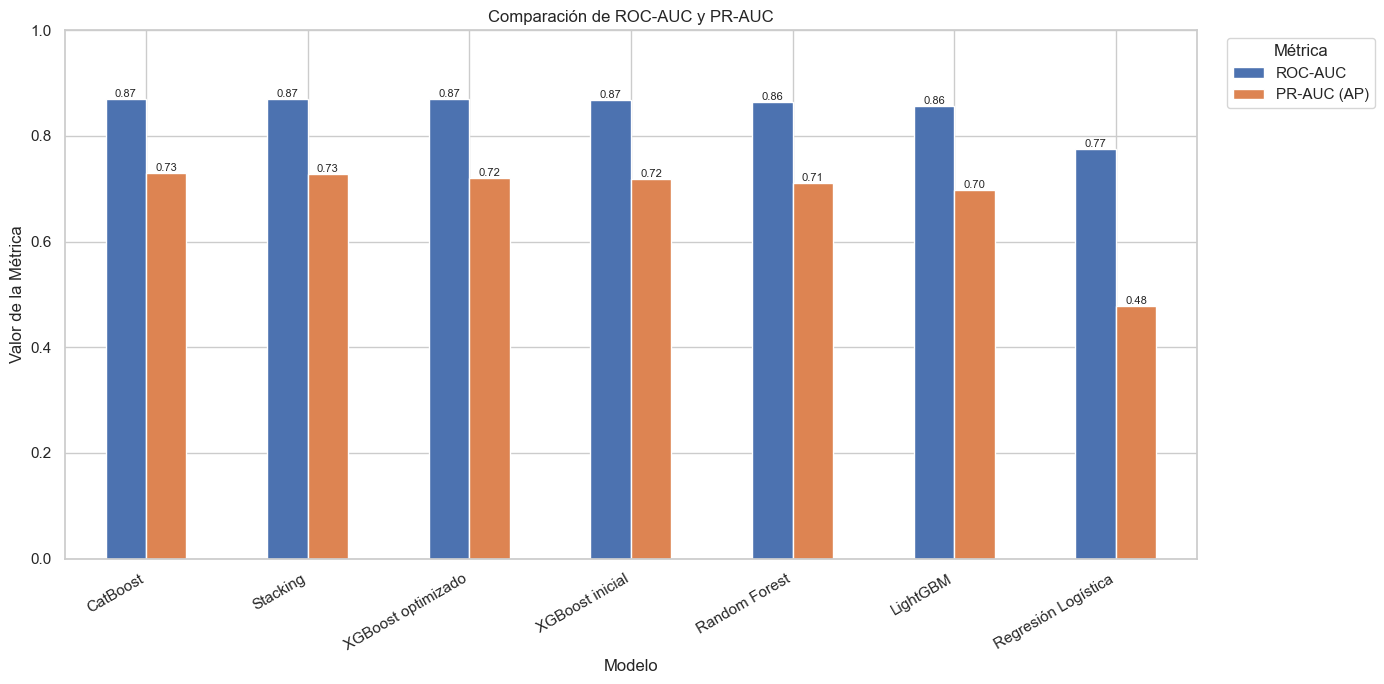

In [106]:
# Métricas basadas en probabilidades

metricas_probabilidades = [

    "ROC-AUC",

    "PR-AUC (AP)"

]


# Preparación de la tabla

tabla_grafico_probabilidades = (

    tabla_comparacion_visual[

        [

            "Modelo"

        ]

        +

        metricas_probabilidades

    ]

    .set_index(

        "Modelo"

    )

)


# Creación del gráfico

ax = (

    tabla_grafico_probabilidades

    .plot(

        kind="bar",

        figsize=(14, 7)

    )

)


ax.set_title(

    "Comparación de ROC-AUC "
    "y PR-AUC"

)

ax.set_xlabel(

    "Modelo"

)

ax.set_ylabel(

    "Valor de la Métrica"

)

ax.set_ylim(

    0,

    1

)

plt.xticks(

    rotation=30,

    ha="right"

)


# Etiquetas sobre las barras

for contenedor in ax.containers:

    ax.bar_label(

        contenedor,

        fmt="%.2f",

        fontsize=8

    )


plt.legend(

    title="Métrica",

    bbox_to_anchor=(

        1.02,

        1

    ),

    loc="upper left"

)

plt.tight_layout()

plt.show()

Los modelos basados en árboles alcanzaron valores similares de ROC-AUC, cercanos a 0,86 y 0,87.

Las diferencias resultan más visibles mediante PR-AUC.

La Regresión Logística obtuvo una PR-AUC de aproximadamente 0,48, mientras que los modelos complejos alcanzaron valores entre 0,70 y 0,73.

CatBoost y Stacking presentaron las mayores PR-AUC sobre el conjunto de prueba.

##### 15.3 Curvas ROC

La curva ROC representa la relación entre:

- Tasa de verdaderos positivos.
- Tasa de falsos positivos.

Un modelo presenta una mejor capacidad de separación cuando su curva se aproxima a la esquina superior izquierda.

El área bajo la curva se resume mediante ROC-AUC.

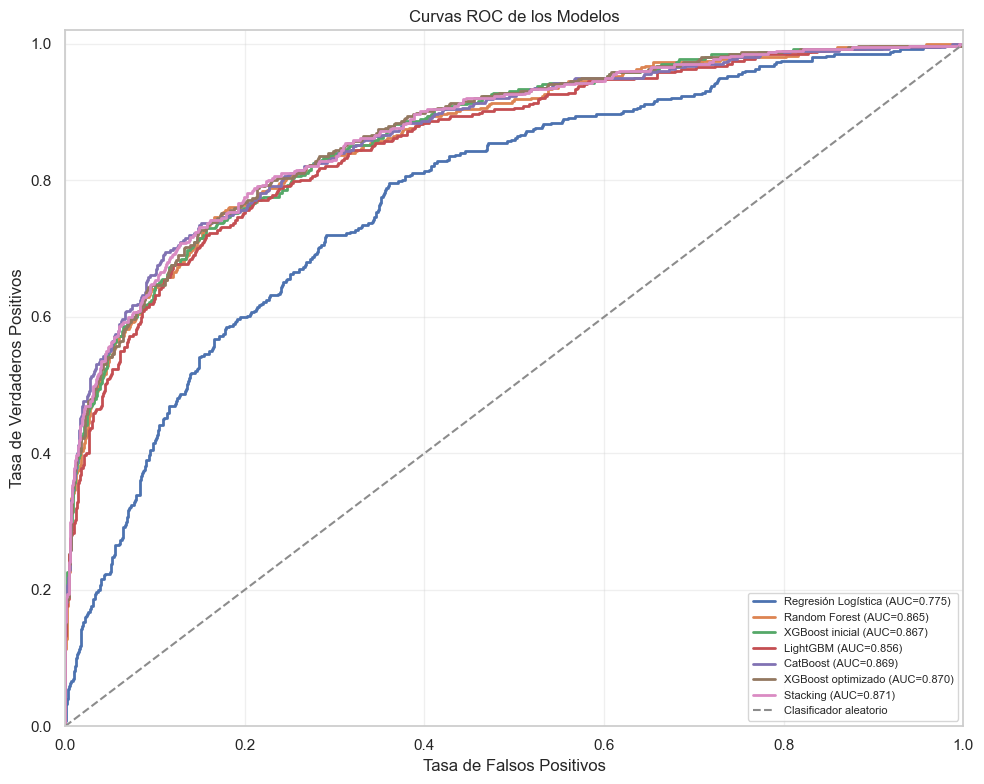

In [107]:
# Herramientas para las curvas de evaluación

from sklearn.metrics import (

    roc_curve,

    auc,

    precision_recall_curve

)


# Creación del gráfico

plt.figure(

    figsize=(10, 8)

)


# Curva ROC de cada modelo

for nombre_modelo in modelos_evaluados:

    probabilidades = (

        resultados_modelos[

            nombre_modelo

        ][

            "y_prob"

        ]

    )


    fpr, tpr, _ = roc_curve(

        y_test,

        probabilidades

    )


    valor_auc = auc(

        fpr,

        tpr

    )


    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=(

            f"{nombre_modelo} "

            f"(AUC={valor_auc:.3f})"

        )

    )


# Línea de referencia

plt.plot(

    [

        0,

        1

    ],

    [

        0,

        1

    ],

    linestyle="--",

    label="Clasificador aleatorio"

)


plt.title(

    "Curvas ROC de los Modelos"

)

plt.xlabel(

    "Tasa de Falsos Positivos"

)

plt.ylabel(

    "Tasa de Verdaderos Positivos"

)

plt.xlim(

    0,

    1

)

plt.ylim(

    0,

    1.02

)

plt.legend(

    loc="lower right",

    fontsize=8

)

plt.grid(

    alpha=0.3

)

plt.tight_layout()

plt.show()

Las curvas ROC muestran una mejora clara de los modelos complejos respecto de la Regresión Logística.

XGBoost, CatBoost y Stacking presentan curvas similares, lo que coincide con los valores cercanos de ROC-AUC.

Debido a que las clases se encuentran desbalanceadas, la curva ROC debe interpretarse junto con la curva Precision-Recall.

##### 15.4 Curvas Precision-Recall

La curva Precision-Recall representa la relación entre:

- Precision.
- Recall.

Esta curva es especialmente informativa cuando la clase positiva es minoritaria.

La línea horizontal representa la proporción de clientes que abandonaron dentro del conjunto de prueba.

Un modelo presenta un mejor desempeño cuando mantiene valores elevados de Precision a medida que aumenta Recall

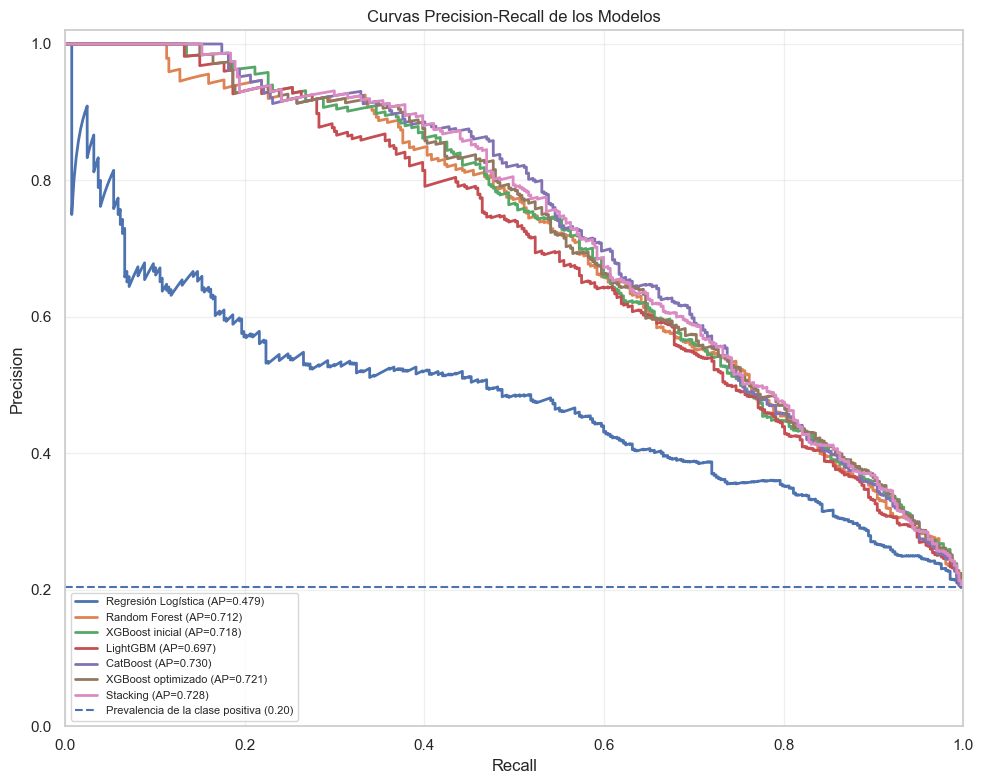

In [108]:
# Proporción de la clase positiva en el conjunto de prueba

prevalencia_clase_positiva = (

    y_test.mean()

)


# Creación del gráfico

plt.figure(

    figsize=(10, 8)

)


# Curva Precision-Recall
# de cada modelo

for nombre_modelo in modelos_evaluados:

    probabilidades = (

        resultados_modelos[

            nombre_modelo

        ][

            "y_prob"

        ]

    )


    precision, recall, _ = (

        precision_recall_curve(

            y_test,

            probabilidades

        )

    )


    average_precision = (

        average_precision_score(

            y_test,

            probabilidades

        )

    )


    plt.plot(

        recall,

        precision,

        linewidth=2,

        label=(

            f"{nombre_modelo} "

            f"(AP={average_precision:.3f})"

        )

    )


# Línea correspondiente
# a la prevalencia

plt.axhline(

    y=(

        prevalencia_clase_positiva

    ),

    linestyle="--",

    label=(

        "Prevalencia de la clase positiva "

        f"({prevalencia_clase_positiva:.2f})"

    )

)


plt.title(

    "Curvas Precision-Recall "
    "de los Modelos"

)

plt.xlabel(

    "Recall"

)

plt.ylabel(

    "Precision"

)

plt.xlim(

    0,

    1

)

plt.ylim(

    0,

    1.02

)

plt.legend(

    loc="lower left",

    fontsize=8

)

plt.grid(

    alpha=0.3

)

plt.tight_layout()

plt.show()

Las curvas Precision-Recall muestran con mayor claridad las diferencias entre los modelos.

La Regresión Logística presenta el rendimiento más bajo.

Los modelos basados en árboles mantienen una relación más favorable entre Precision y Recall.

CatBoost y Stacking alcanzan las mayores PR-AUC, aunque CatBoost presenta un mejor equilibrio general de métricas y una matriz de confusión ligeramente superior.

Por esta razón, CatBoost continúa siendo el modelo seleccionado

##### 15.5 Conclusión de la Comparación Visual

La comparación gráfica confirmó los resultados observados en las tablas.

Los modelos de ensamble y Gradient Boosting superaron ampliamente a la Regresión Logística baseline.

CatBoost presentó:

- La mayor Accuracy.
- Una de las mayores Precision.
- El mayor Recall junto con otros modelos.
- El mayor F1-Score.
- Una de las mayores ROC-AUC.
- La mayor PR-AUC junto con Stacking.

Aunque Stacking obtuvo una PR-AUC similar, no produjo una mejora suficiente para compensar su mayor complejidad.

**CatBoost** quedo elegido como el mejor modelo debido a su rendimiento general, su equilibrio entre Precision y Recall y su menor complejidad operacional.

#### 16. Importancia de Variables del Modelo CatBoost

*CatBoost* fue seleccionado como el modelo final debido a que presentó el mejor equilibrio general entre las métricas evaluadas.

Aunque CatBoost y Stacking obtuvieron valores similares de PR-AUC, CatBoost alcanzó mejores resultados de Accuracy, Precision y F1-Score, presentó una matriz de confusión ligeramente superior y posee una estructura menos compleja.

Por lo tanto, se analizará la importancia de las variables utilizadas por CatBoost.

La importancia de variables permite estimar cuánto contribuyó cada característica a las predicciones generadas por el modelo.

##### 16.1 Recuperación del Pipeline Entrenado

La función de evaluación almacenó el Pipeline ajustado dentro del diccionario de resultados.

A partir de ese Pipeline se recuperarán:

- El preprocesador entrenado.
- El modelo CatBoost entrenado.

El preprocesador permitirá recuperar los nombres de las variables después de aplicar el escalamiento y el One-Hot Encoding.

In [109]:
# Recuperación del Pipeline CatBoost ya entrenado

pipeline_catboost_ajustado = (

    resultado_catboost[

        "modelo"

    ]

)


# Recuperación del
# preprocesador ajustado

preprocesador_catboost_ajustado = (

    pipeline_catboost_ajustado

    .named_steps[

        "preprocesamiento"

    ]

)


# Recuperación del
# modelo CatBoost ajustado

modelo_catboost_ajustado = (

    pipeline_catboost_ajustado

    .named_steps[

        "modelo"

    ]

)


print(

    "Pipeline, preprocesador y modelo "

    "recuperados correctamente."

)

Pipeline, preprocesador y modelo recuperados correctamente.


##### 16.2 Recuperación de los Nombres de las Variables

Después del preprocesamiento, las variables categóricas fueron transformadas mediante One-Hot Encoding.

Por este motivo, algunas variables originales generan nuevas columnas.

Por ejemplo:

- `Geography` genera variables asociadas a diferentes países.
- `Gender` genera una variable binaria asociada a una de sus categorías.

Se recuperarán los nombres finales para relacionar correctamente cada importancia con la variable correspondiente

In [110]:
# Nombres de las variables después del preprocesamiento

nombres_variables_catboost = (

    preprocesador_catboost_ajustado

    .get_feature_names_out()

)


# Importancias calculadas
# por CatBoost

importancias_catboost = (

    modelo_catboost_ajustado

    .get_feature_importance()

)


print(

    f"Cantidad de variables transformadas: "

    f"{len(nombres_variables_catboost)}"

)


print(

    f"Cantidad de importancias obtenidas: "

    f"{len(importancias_catboost)}"

)

Cantidad de variables transformadas: 11
Cantidad de importancias obtenidas: 11


In [111]:
# Verificación de consistencia

if (

    len(

        nombres_variables_catboost

    )

    !=

    len(

        importancias_catboost

    )

):

    raise ValueError(

        "La cantidad de nombres de variables "

        "no coincide con la cantidad "

        "de importancias."

    )


print(

    "La cantidad de variables y "

    "de importancias coincide."

)

La cantidad de variables y de importancias coincide.


##### 16.3 Importancia de las Variables Transformadas

Se construirá una tabla ordenada desde la variable más importante hasta la menos importante.

Las importancias serán expresadas como porcentajes para facilitar su interpretación.

También se calculará la importancia acumulada

In [112]:
# Normalización de importancias

importancias_porcentaje = (

    importancias_catboost

    /

    importancias_catboost.sum()

    *

    100

)


# Creación de la tabla

tabla_importancias_catboost = (

    pd.DataFrame({

        "Variable transformada": (

            nombres_variables_catboost

        ),

        "Importancia": (

            importancias_catboost

        ),

        "Importancia (%)": (

            importancias_porcentaje

        )

    })

)


# Ordenamiento

tabla_importancias_catboost = (

    tabla_importancias_catboost

    .sort_values(

        by="Importancia (%)",

        ascending=False

    )

    .reset_index(

        drop=True

    )

)


# Importancia acumulada

tabla_importancias_catboost[

    "Importancia acumulada (%)"

] = (

    tabla_importancias_catboost[

        "Importancia (%)"

    ]

    .cumsum()

)


# Redondeo para visualización

tabla_importancias_catboost[

    [

        "Importancia",

        "Importancia (%)",

        "Importancia acumulada (%)"

    ]

] = (

    tabla_importancias_catboost[

        [

            "Importancia",

            "Importancia (%)",

            "Importancia acumulada (%)"

        ]

    ]

    .round(2)

)


tabla_importancias_catboost

,Variable transformada,Importancia,Importancia (%),Importancia acumulada (%)
0,NumOfProducts,24.33,24.33,24.33
1,Age,20.19,20.19,44.52
2,Balance,13.71,13.71,58.22
3,EstimatedSalary,7.98,7.98,66.21
4,CreditScore,7.58,7.58,73.79
5,IsActiveMember,7.42,7.42,81.21
6,Geography_Germany,7.03,7.03,88.24
7,Tenure,5.18,5.18,93.42
8,Gender_Male,3.62,3.62,97.04
9,Geography_Spain,1.87,1.87,98.91


##### 16.4 Visualización de las Variables Transformadas

El siguiente gráfico mostrará las diez variables transformadas con mayor importancia.

Las variables aparecerán ordenadas de menor a mayor dentro del gráfico para que la característica más importante quede ubicada en la parte superior

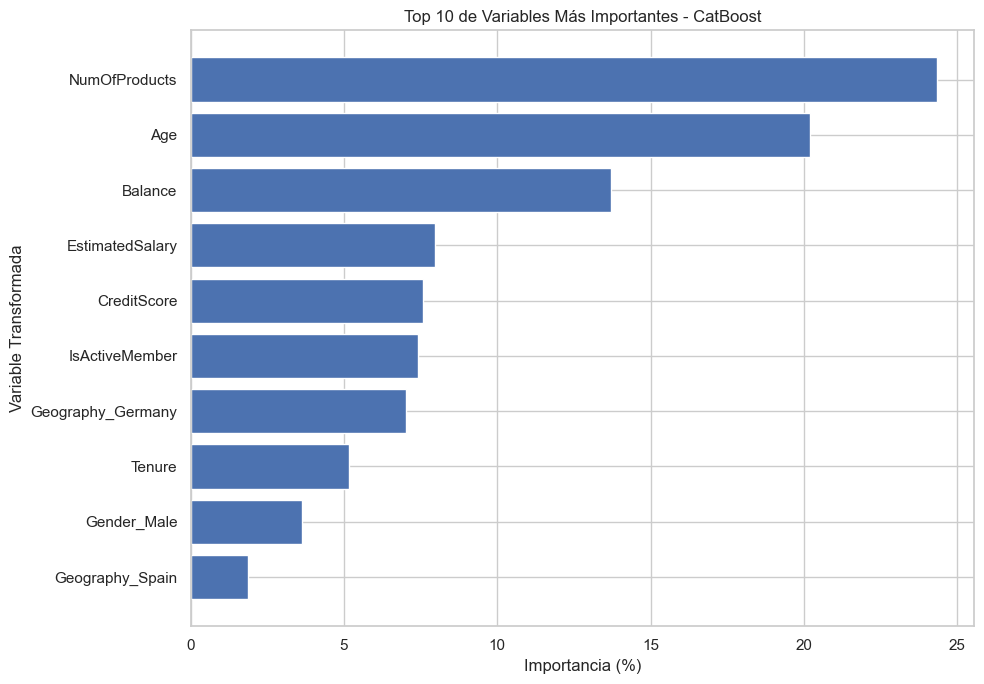

In [113]:
# Selección de las diez variables más importantes

top_10_variables_catboost = (

    tabla_importancias_catboost

    .head(10)

    .sort_values(

        by="Importancia (%)",

        ascending=True

    )

)


# Creación del gráfico

plt.figure(

    figsize=(10, 7)

)


plt.barh(

    top_10_variables_catboost[

        "Variable transformada"

    ],

    top_10_variables_catboost[

        "Importancia (%)"

    ]

)


plt.title(

    "Top 10 de Variables Más Importantes - CatBoost"

)


plt.xlabel(

    "Importancia (%)"

)


plt.ylabel(

    "Variable Transformada"

)


plt.tight_layout()


plt.show()

##### 16.5 Importancia Agrupada por Variable Original

Las variables categóricas fueron transformadas mediante One-Hot Encoding.

Como consecuencia, una misma variable original puede estar representada mediante varias columnas.

Por ejemplo:

- Las categorías generadas a partir de `Geography` pertenecen a una única variable original.
- La columna generada a partir de `Gender` pertenece a la variable original `Gender`.

Para facilitar la interpretación, las importancias correspondientes a una misma variable categórica serán agrupadas.

Las variables numéricas y binarias conservarán su nombre original

In [114]:
# Función para identificar la variable original

def obtener_variable_original(

    nombre_variable

):

    """

    Agrupa las variables generadas

    mediante One-Hot Encoding

    con su variable original.

    """


    for variable_categorica in (

        variables_categoricas

    ):

        if nombre_variable.startswith(

            f"{variable_categorica}_"

        ):

            return (

                variable_categorica

            )


    return nombre_variable

In [115]:
# Aplicación de la función

tabla_importancias_agrupadas = (

    tabla_importancias_catboost

    .copy()

)


tabla_importancias_agrupadas[

    "Variable original"

] = (

    tabla_importancias_agrupadas[

        "Variable transformada"

    ]

    .apply(

        obtener_variable_original

    )

)


# Agrupación de importancias

tabla_importancias_originales = (

    tabla_importancias_agrupadas

    .groupby(

        "Variable original",

        as_index=False

    )

    [

        "Importancia (%)"

    ]

    .sum()

)


# Ordenamiento

tabla_importancias_originales = (

    tabla_importancias_originales

    .sort_values(

        by="Importancia (%)",

        ascending=False

    )

    .reset_index(

        drop=True

    )

)


# Importancia acumulada

tabla_importancias_originales[

    "Importancia acumulada (%)"

] = (

    tabla_importancias_originales[

        "Importancia (%)"

    ]

    .cumsum()

)


# Redondeo

tabla_importancias_originales[

    [

        "Importancia (%)",

        "Importancia acumulada (%)"

    ]

] = (

    tabla_importancias_originales[

        [

            "Importancia (%)",

            "Importancia acumulada (%)"

        ]

    ]

    .round(2)

)


tabla_importancias_originales

,Variable original,Importancia (%),Importancia acumulada (%)
0,NumOfProducts,24.33,24.33
1,Age,20.19,44.52
2,Balance,13.71,58.23
3,Geography,8.90,67.13
4,EstimatedSalary,7.98,75.11
5,CreditScore,7.58,82.69
6,IsActiveMember,7.42,90.11
7,Tenure,5.18,95.29
8,Gender,3.62,98.91
9,HasCrCard,1.09,100.00


##### 16.6 Visualización por Variable Original

La importancia agrupada permite interpretar el aporte total de cada característica original.

Esta representación resulta más adecuada para el análisis de negocio, ya que evita analizar por separado las categorías generadas mediante One-Hot Encoding.

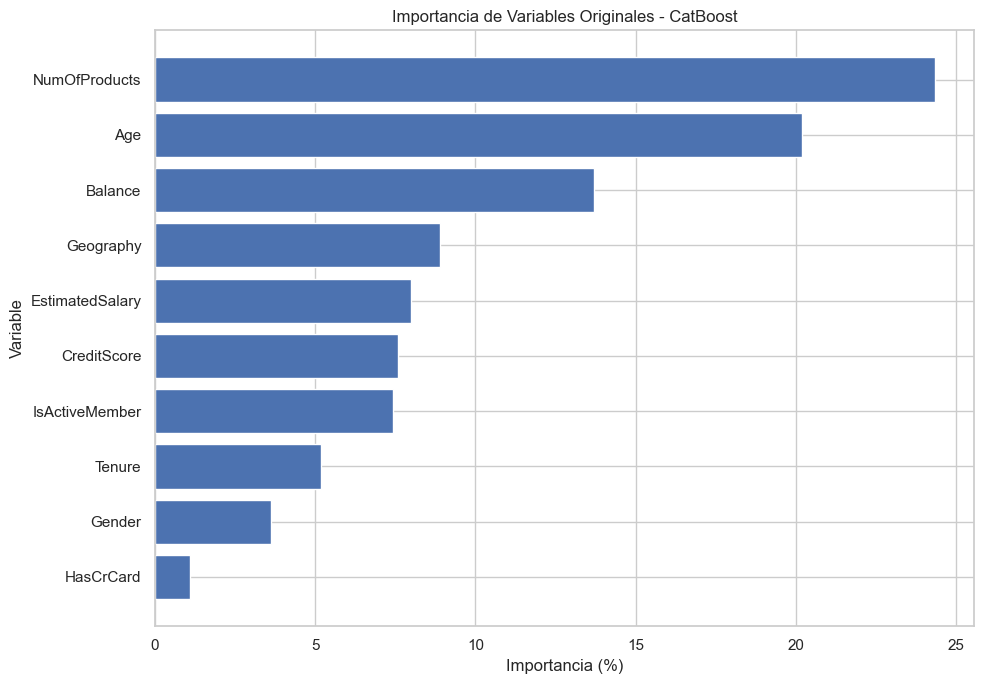

In [116]:
# Ordenar para el gráfico horizontal

tabla_grafico_importancias = (

    tabla_importancias_originales

    .sort_values(

        by="Importancia (%)",

        ascending=True

    )

)


# Creación del gráfico

plt.figure(

    figsize=(10, 7)

)


plt.barh(

    tabla_grafico_importancias[

        "Variable original"

    ],

    tabla_grafico_importancias[

        "Importancia (%)"

    ]

)


plt.title(

    "Importancia de Variables Originales - CatBoost"

)


plt.xlabel(

    "Importancia (%)"

)


plt.ylabel(

    "Variable"

)


plt.tight_layout()


plt.show()

##### 16.7 Variables con Mayor Influencia

Se mostrarán las cinco variables originales con mayor importancia.

Estas características serán utilizadas posteriormente para interpretar los principales factores asociados a las predicciones de churn

In [117]:
# Cinco variables originales con mayor importancia

top_5_variables_catboost = (

    tabla_importancias_originales

    .head(5)

    .copy()

)


top_5_variables_catboost

,Variable original,Importancia (%),Importancia acumulada (%)
0,NumOfProducts,24.33,24.33
1,Age,20.19,44.52
2,Balance,13.71,58.23
3,Geography,8.90,67.13
4,EstimatedSalary,7.98,75.11


##### Consideraciones para Interpretar la Importancia de Variables

La importancia de una variable indica cuánto contribuyó al proceso predictivo del modelo.

Una importancia elevada significa que CatBoost utilizó con mayor frecuencia o intensidad la información contenida en esa característica para generar predicciones.

Sin embargo, la importancia no permite determinar:

- Si la variable aumenta o disminuye la probabilidad de abandono.
- La magnitud exacta del efecto sobre la probabilidad.
- Una relación causal entre la variable y el churn.

Por lo tanto, la importancia debe interpretarse como una medida de relevancia predictiva y no como evidencia de causalidad.

Además, una importancia reducida no significa necesariamente que la variable carezca completamente de información. Su aporte puede encontrarse relacionado con interacciones o patrones compartidos con otras características

##### Importancia Nativa de CatBoost

La importancia fue calculada mediante el método nativo `get_feature_importance()` de CatBoost.

En este tipo de modelo, la importancia representa el efecto de las variables sobre los valores generados por las predicciones.

Esta medida no debe interpretarse exactamente como el concepto de `gain` utilizado por XGBoost.

Cada algoritmo puede calcular la importancia mediante criterios diferentes. Por este motivo, las importancias se utilizarán principalmente para analizar el modelo CatBoost y no para comparar directamente valores de importancia entre algoritmos distintos

##### Interpretación de la Importancia de Variables

El análisis de importancia mostró que CatBoost concentró gran parte de su capacidad predictiva en un conjunto reducido de variables.

Las cinco características con mayor importancia fueron:

1. `NumOfProducts`: 24,33%.
2. `Age`: 20,19%.
3. `Balance`: 13,71%.
4. `Geography`: 8,90%.
5. `EstimatedSalary`: 7,98%.

Estas cinco variables acumularon aproximadamente el 75,11% de la importancia total.

`NumOfProducts` fue la característica más relevante. Esto indica que la cantidad de productos contratados aportó información importante para diferenciar clientes con distintos niveles de riesgo de abandono.

`Age` ocupó el segundo lugar, con una importancia de 20,19%. CatBoost pudo utilizar esta variable para detectar relaciones no lineales entre diferentes rangos etarios y el comportamiento de churn.

`Balance` alcanzó una importancia de 13,71% y constituyó la tercera variable más relevante. Esto sugiere que los patrones asociados al saldo de los clientes contribuyeron de manera significativa a las predicciones.

`Geography` presentó una importancia agrupada de 8,90%. Dentro de las variables generadas mediante One-Hot Encoding, `Geography_Germany` aportó 7,03% y `Geography_Spain` 1,87%.

Francia no aparece como una variable independiente debido a que fue utilizada como categoría de referencia mediante `drop="first"`. Su información se encuentra representada implícitamente cuando las demás categorías toman el valor cero.

`EstimatedSalary` completó el grupo de las cinco variables principales, con una importancia de 7,98%.

Las variables `CreditScore`, `IsActiveMember` y `Tenure` presentaron niveles de importancia intermedios, con valores de 7,58%, 7,42% y 5,18%, respectivamente.

Por último, `Gender` y `HasCrCard` fueron las variables con menor importancia, con valores de 3,62% y 1,09%.

Los resultados indican que CatBoost utilizó principalmente información relacionada con:

- La cantidad de productos contratados.
- La edad del cliente.
- El saldo disponible.
- La ubicación geográfica.
- Las características económicas.

Sin embargo, la importancia de variables no indica la dirección del efecto.

Por ejemplo, no permite afirmar si una mayor cantidad de productos aumenta o disminuye la probabilidad de abandono.

Tampoco permite establecer relaciones causales.

Por lo tanto, los resultados deben interpretarse como medidas de relevancia predictiva dentro del modelo CatBoost y no como evidencia de causalidad.

#### 17. Selección del mejor Modelo

La selección del modelo final no se realizará utilizando una única métrica.

Se considerarán conjuntamente:

- PR-AUC como métrica principal.
- Recall.
- Precision.
- F1-Score.
- ROC-AUC.
- Matriz de confusión.
- Estabilidad entre validación cruzada y prueba.
- Complejidad de implementación.

PR-AUC tendrá mayor relevancia debido al desbalance existente en la variable objetivo.

##### 17.1 Comparación entre los Dos Mejores Modelos

CatBoost y Stacking obtuvieron las mayores PR-AUC sobre el conjunto de prueba.

Ambos alcanzaron un valor aproximado de 0,73.

Debido a que los resultados fueron cercanos, se realizará una comparación más detallada utilizando los valores completos almacenados antes del redondeo.

In [118]:
# Comparación detallada entre CatBoost y Stacking

modelos_finalistas = [

    "CatBoost",

    "Stacking"

]


tabla_finalistas = pd.DataFrame(

    [

        resultados_modelos[
            nombre_modelo
        ][
            "metricas_test"
        ]

        for nombre_modelo
        in modelos_finalistas

    ]

)


# Selección de métricas

tabla_finalistas = (

    tabla_finalistas[

        [

            "Modelo",

            "Accuracy",

            "Precision",

            "Recall",

            "F1-Score",

            "ROC-AUC",

            "PR-AUC (AP)",

            "CV PR-AUC media",

            "CV PR-AUC desvío"

        ]

    ]

)


# Copia para mostrar

tabla_finalistas_mostrar = (

    tabla_finalistas

    .copy()

)


# Redondeo a seis decimales
# para observar diferencias pequeñas

columnas_numericas_finalistas = (

    tabla_finalistas_mostrar

    .select_dtypes(

        include="number"

    )

    .columns

)


tabla_finalistas_mostrar[

    columnas_numericas_finalistas

] = (

    tabla_finalistas_mostrar[

        columnas_numericas_finalistas

    ]

    .round(6)

)


tabla_finalistas_mostrar

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP),CV PR-AUC media,CV PR-AUC desvío
0,CatBoost,0.88,0.82,0.50,0.62,0.87,0.73,0.71,0.02
1,Stacking,0.87,0.79,0.50,0.61,0.87,0.73,0.71,0.02


In [119]:
# Diferencias entre CatBoost y Stacking

metricas_finalistas = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]


comparacion_cat_vs_stacking = pd.DataFrame({

    "Métrica": (

        metricas_finalistas

    ),

    "CatBoost": [

        resultado_catboost[

            "metricas_test"

        ][metrica]

        for metrica
        in metricas_finalistas

    ],

    "Stacking": [

        resultado_stacking[

            "metricas_test"

        ][metrica]

        for metrica
        in metricas_finalistas

    ]

})


comparacion_cat_vs_stacking[

    "Diferencia CatBoost - Stacking"

] = (

    comparacion_cat_vs_stacking[

        "CatBoost"

    ]

    -

    comparacion_cat_vs_stacking[

        "Stacking"

    ]

)


# Redondeo

columnas_comparacion_finalistas = (

    comparacion_cat_vs_stacking

    .select_dtypes(

        include="number"

    )

    .columns

)


comparacion_cat_vs_stacking[

    columnas_comparacion_finalistas

] = (

    comparacion_cat_vs_stacking[

        columnas_comparacion_finalistas

    ]

    .round(6)

)


comparacion_cat_vs_stacking

,Métrica,CatBoost,Stacking,Diferencia CatBoost - Stacking
0,Accuracy,0.88,0.87,0.01
1,Precision,0.82,0.79,0.03
2,Recall,0.50,0.50,0.00
3,F1-Score,0.62,0.61,0.01
4,ROC-AUC,0.87,0.87,-0.00
5,PR-AUC (AP),0.73,0.73,0.00


La comparación muestra que CatBoost y Stacking presentan resultados muy similares.

CatBoost fue seleccionado porque:

- Alcanzó una PR-AUC equivalente o ligeramente superior.
- Obtuvo mayor Accuracy.
- Obtuvo mayor Precision.
- Alcanzó mayor F1-Score.
- Presentó una matriz de confusión ligeramente mejor.
- Requiere una estructura menos compleja que Stacking.

Stacking necesita entrenar tres modelos base y un meta-modelo.

CatBoost utiliza un único algoritmo y alcanza un rendimiento igual o superior en las principales métricas.

Por lo tanto, la complejidad adicional de Stacking no produjo una mejora suficiente para justificar su selección

##### 17.2 Modelo Seleccionado

El modelo seleccionado para la predicción de churn es **CatBoost**.

La decisión se fundamenta en los siguientes resultados obtenidos sobre el conjunto de prueba:

- Accuracy: 0,88.
- Precision: 0,82.
- Recall: 0,50.
- F1-Score: 0,62.
- ROC-AUC: 0,87.
- PR-AUC: 0,73.

CatBoost presentó el mejor equilibrio general entre las métricas evaluadas.

Además, obtuvo una matriz de confusión favorable:

- 1.549 verdaderos negativos.
- 44 falsos positivos.
- 202 falsos negativos.
- 205 verdaderos positivos.

Aunque Stacking alcanzó una PR-AUC similar, CatBoost presentó una mayor Precision, un mayor F1-Score y una menor cantidad de falsos positivos.

También posee una estructura más simple, debido a que no requiere entrenar múltiples modelos base y un meta-modelo.

Por estas razones, CatBoost fue seleccionado como el mejor modelo del Avance 2.

##### 17.3 Comparación de CatBoost con la Regresión Logística Baseline

La Regresión Logística fue utilizada como modelo baseline durante el Avance 1.

CatBoost será comparado directamente con ese modelo para medir la ganancia obtenida al utilizar un algoritmo más complejo.

Se calcularán:

- Diferencias absolutas.
- Mejoras relativas.
- Cambios en la matriz de confusión

In [120]:
# Métricas utilizadas para comparar con el baseline

metricas_baseline = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "PR-AUC (AP)"

]


# Creación de tabla

comparacion_catboost_baseline = (

    pd.DataFrame({

        "Métrica": (

            metricas_baseline

        ),

        "Regresión Logística": [

            resultado_logistico[

                "metricas_test"

            ][metrica]

            for metrica
            in metricas_baseline

        ],

        "CatBoost": [

            resultado_catboost[

                "metricas_test"

            ][metrica]

            for metrica
            in metricas_baseline

        ]

    })

)


# Mejora absoluta

comparacion_catboost_baseline[

    "Mejora absoluta"

] = (

    comparacion_catboost_baseline[

        "CatBoost"

    ]

    -

    comparacion_catboost_baseline[

        "Regresión Logística"

    ]

)


# Mejora relativa

comparacion_catboost_baseline[

    "Mejora relativa (%)"

] = (

    comparacion_catboost_baseline[

        "Mejora absoluta"

    ]

    /

    comparacion_catboost_baseline[

        "Regresión Logística"

    ]

    *

    100

)


# Redondeo

columnas_cat_baseline = [

    "Regresión Logística",

    "CatBoost",

    "Mejora absoluta"

]


comparacion_catboost_baseline[

    columnas_cat_baseline

] = (

    comparacion_catboost_baseline[

        columnas_cat_baseline

    ]

    .round(4)

)


comparacion_catboost_baseline[

    "Mejora relativa (%)"

] = (

    comparacion_catboost_baseline[

        "Mejora relativa (%)"

    ]

    .round(2)

)


comparacion_catboost_baseline

,Métrica,Regresión Logística,CatBoost,Mejora absoluta,Mejora relativa (%)
0,Accuracy,0.81,0.88,0.07,8.54
1,Precision,0.59,0.82,0.23,39.74
2,Recall,0.19,0.50,0.32,169.74
3,F1-Score,0.28,0.62,0.34,120.39
4,ROC-AUC,0.77,0.87,0.09,12.21
5,PR-AUC (AP),0.48,0.73,0.25,52.44


##### 17.4 Comparación Visual con el Modelo Baseline

El gráfico permitirá observar la mejora obtenida por CatBoost respecto de la Regresión Logística

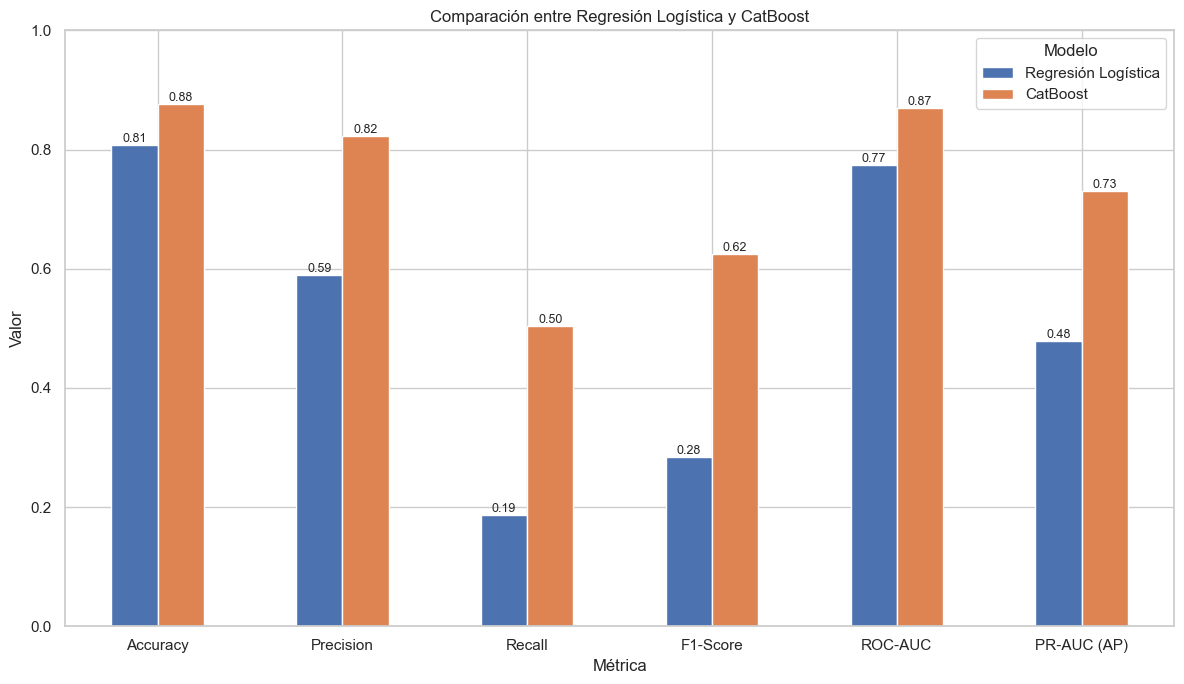

In [121]:
# Preparación de datos

tabla_grafico_cat_baseline = (

    comparacion_catboost_baseline[

        [

            "Métrica",

            "Regresión Logística",

            "CatBoost"

        ]

    ]

    .set_index(

        "Métrica"

    )

)


# Gráfico

ax = (

    tabla_grafico_cat_baseline

    .plot(

        kind="bar",

        figsize=(12, 7)

    )

)


ax.set_title(

    "Comparación entre Regresión Logística y CatBoost"

)


ax.set_xlabel(

    "Métrica"

)


ax.set_ylabel(

    "Valor"

)


ax.set_ylim(

    0,

    1

)


plt.xticks(

    rotation=0

)


# Etiquetas

for contenedor in ax.containers:

    ax.bar_label(

        contenedor,

        fmt="%.2f",

        fontsize=9

    )


plt.legend(

    title="Modelo"

)


plt.tight_layout()


plt.show()

CatBoost superó a la Regresión Logística en todas las métricas evaluadas.

Las mejoras más importantes se observaron en:

- Recall.
- F1-Score.
- PR-AUC.

Esto indica una mayor capacidad para identificar clientes que abandonaron y un mejor equilibrio entre detección y precisión.

La mejora no se limitó a Accuracy.

El modelo también aumentó significativamente la capacidad de identificar la clase positiva.

##### 17.5 Cambios en la Matriz de Confusión

Se analizarán los cambios producidos por CatBoost respecto de la Regresión Logística.

Los falsos negativos son especialmente relevantes, debido a que representan clientes que abandonaron, pero no fueron identificados por el modelo.

In [122]:
# Componentes de la matriz de Regresión Logística

tn_log, fp_log, fn_log, tp_log = (

    resultado_logistico[

        "matriz_confusion"

    ]

    .ravel()

)


# Componentes de la matriz
# de CatBoost

tn_cat_final, fp_cat_final, fn_cat_final, tp_cat_final = (

    resultado_catboost[

        "matriz_confusion"

    ]

    .ravel()

)


# Tabla comparativa

comparacion_matrices_final = pd.DataFrame({

    "Resultado": [

        "Verdaderos negativos",

        "Falsos positivos",

        "Falsos negativos",

        "Verdaderos positivos"

    ],

    "Regresión Logística": [

        tn_log,

        fp_log,

        fn_log,

        tp_log

    ],

    "CatBoost": [

        tn_cat_final,

        fp_cat_final,

        fn_cat_final,

        tp_cat_final

    ]

})


# Cambio

comparacion_matrices_final[

    "Cambio CatBoost - Baseline"

] = (

    comparacion_matrices_final[

        "CatBoost"

    ]

    -

    comparacion_matrices_final[

        "Regresión Logística"

    ]

)


comparacion_matrices_final

,Resultado,Regresión Logística,CatBoost,Cambio CatBoost - Baseline
0,Verdaderos negativos,1540,1549,9
1,Falsos positivos,53,44,-9
2,Falsos negativos,331,202,-129
3,Verdaderos positivos,76,205,129


CatBoost produjo una mejora importante en la detección de clientes que abandonaron.

Respecto de la Regresión Logística:

- Los verdaderos positivos aumentaron de 76 a 205.
- Los falsos negativos disminuyeron de 331 a 202.
- Los falsos positivos disminuyeron de 53 a 44.
- Los verdaderos negativos aumentaron de 1.540 a 1.549.

CatBoost identificó correctamente 129 clientes adicionales que abandonaron.

Al mismo tiempo, redujo nueve falsas alertas.

Por lo tanto, la mejora en Recall no se produjo a costa de una pérdida de Precision.

El modelo logró mejorar simultáneamente la detección de churn y la calidad de las predicciones positivas.

##### 17.6 Fortalezas del Modelo Seleccionado

Las principales fortalezas de CatBoost son:

- Mejor rendimiento general entre los modelos evaluados.
- PR-AUC elevada para un problema con clases desbalanceadas.
- Mayor capacidad para detectar clientes que abandonaron.
- Buen equilibrio entre Precision y Recall.
- Menor cantidad de falsos positivos que Stacking.
- Capacidad para modelar relaciones no lineales.
- Capacidad para capturar interacciones entre variables.
- Menor complejidad operacional que un ensamble Stacking.
- Posibilidad de obtener importancia de variables.

##### 17.7 Limitaciones del Modelo Seleccionado

A pesar de los buenos resultados, CatBoost presenta algunas limitaciones:

- Aproximadamente la mitad de los clientes que abandonaron todavía no fue detectada.
- El modelo es menos interpretable que la Regresión Logística.
- La importancia de variables no permite conocer directamente la dirección de los efectos.
- Las relaciones identificadas son predictivas y no causales.
- El rendimiento fue evaluado sobre un único dataset.
- No se analizaron cambios temporales en el comportamiento de los clientes.
- No se incorporaron costos económicos asociados a falsos positivos y falsos negativos.
- Se mantuvo el umbral predeterminado de 0,5.

#### 18. Conclusiones Técnicas y de Negocio

El Avance 2 tuvo como objetivo implementar y comparar diferentes modelos de ensamble y Gradient Boosting para mejorar la predicción de abandono de clientes.

Los modelos evaluados fueron:

- Regresión Logística baseline.
- Random Forest.
- XGBoost inicial.
- LightGBM.
- CatBoost.
- XGBoost optimizado mediante Grid Search.
- Stacking.

Todos los modelos fueron evaluados mediante un protocolo común que incluyó:

- División estratificada entre entrenamiento y prueba.
- Validación cruzada mediante `StratifiedKFold`.
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.
- PR-AUC.

La métrica principal fue PR-AUC debido al desbalance existente entre las clases.

##### 18.1 Síntesis de Resultados

Síntesis de Resultados

Los modelos basados en árboles superaron ampliamente a la Regresión Logística baseline.

Los principales resultados obtenidos sobre el conjunto de prueba fueron:

| Modelo | Accuracy | Precision | Recall | F1-Score | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Regresión Logística | 0,81 | 0,59 | 0,19 | 0,28 | 0,77 | 0,48 |
| Random Forest | 0,87 | 0,82 | 0,44 | 0,58 | 0,86 | 0,71 |
| XGBoost inicial | 0,87 | 0,78 | 0,49 | 0,60 | 0,87 | 0,72 |
| LightGBM | 0,86 | 0,74 | 0,49 | 0,59 | 0,86 | 0,70 |
| CatBoost | 0,88 | 0,82 | 0,50 | 0,62 | 0,87 | 0,73 |
| XGBoost optimizado | 0,87 | 0,79 | 0,50 | 0,61 | 0,87 | 0,72 |
| Stacking | 0,87 | 0,79 | 0,50 | 0,61 | 0,87 | 0,73 |

CatBoost presentó el mejor equilibrio general entre las métricas y fue seleccionado como modelo final.

##### 18.2 Conclusiones Técnicas

Los resultados permitieron obtener las siguientes conclusiones:

1. Los modelos basados en árboles lograron capturar relaciones no lineales e interacciones que la Regresión Logística no pudo representar con la misma efectividad.

2. Random Forest produjo una mejora importante respecto del baseline y demostró que el uso de múltiples árboles permite obtener una mayor capacidad predictiva.

3. XGBoost inicial presentó un rendimiento competitivo y alcanzó una PR-AUC de 0,72.

4. La optimización mediante Grid Search seleccionó una configuración con árboles menos profundos:

   - `n_estimators=300`.
   - `learning_rate=0.05`.
   - `max_depth=3`.
   - `subsample=0.80`.
   - `colsample_bytree=0.80`.
   - `reg_lambda=1`.

5. La optimización produjo mejoras pequeñas en Precision, Recall y F1-Score, aunque PR-AUC se mantuvo prácticamente estable.

6. LightGBM obtuvo resultados competitivos y mostró una buena capacidad de detección, aunque presentó una Precision inferior a la de los mejores modelos.

7. Stacking combinó correctamente XGBoost, LightGBM y CatBoost mediante una Regresión Logística regularizada.

8. El ensamble Stacking no logró superar claramente al mejor modelo individual.

9. CatBoost obtuvo el mejor equilibrio entre rendimiento, estabilidad y complejidad de implementación.

10. Los resultados de validación cruzada fueron consistentes con las métricas obtenidas sobre el conjunto de prueba y no mostraron señales evidentes de pérdida de generalización

##### 18.3 Resultado del Modelo Seleccionado

CatBoost obtuvo los siguientes resultados:

- Accuracy: 0,88.
- Precision: 0,82.
- Recall: 0,50.
- F1-Score: 0,62.
- ROC-AUC: 0,87.
- PR-AUC: 0,73.

La matriz de confusión mostró:

- 1.549 verdaderos negativos.
- 44 falsos positivos.
- 202 falsos negativos.
- 205 verdaderos positivos.

El modelo identificó correctamente aproximadamente la mitad de los clientes que abandonaron.

Además, aproximadamente el 82% de los clientes clasificados como posibles abandonos correspondió efectivamente a la clase positiva.

Aunque el rendimiento representa una mejora importante respecto del baseline, todavía existen 202 clientes que abandonaron y no fueron detectados.

Por lo tanto, el modelo presenta una capacidad predictiva favorable.

##### 18.4 Mejora Frente a la Regresión Logística Baseline

CatBoost superó a la Regresión Logística en todas las métricas evaluadas.

Las principales mejoras fueron:

- Accuracy aumentó aproximadamente desde 0,81 hasta 0,88.
- Precision aumentó desde 0,59 hasta 0,82.
- Recall aumentó desde 0,19 hasta 0,50.
- F1-Score aumentó desde 0,28 hasta 0,62.
- ROC-AUC aumentó desde 0,77 hasta 0,87.
- PR-AUC aumentó desde 0,48 hasta 0,73.

La mejora más relevante se observó en la detección de clientes que abandonaron.

Los verdaderos positivos aumentaron:

- Regresión Logística: 76.
- CatBoost: 205.

Los falsos negativos disminuyeron:

- Regresión Logística: 331.
- CatBoost: 202.

CatBoost logró identificar correctamente 129 clientes adicionales que abandonaron.

Además, redujo los falsos positivos de 53 a 44.

Esto significa que la mejora en Recall no produjo un deterioro de Precision

##### 18.5 Interpretación de Negocio

El modelo CatBoost puede utilizarse como una herramienta de apoyo para priorizar clientes según su probabilidad estimada de abandono.

Las probabilidades generadas por el modelo permiten ordenar a los clientes desde menor hasta mayor riesgo.

Esta información podría ayudar al equipo de retención a:

- Priorizar el contacto con clientes de mayor riesgo.
- Asignar recursos comerciales de manera más eficiente.
- Diseñar campañas diferenciadas según el nivel de riesgo.
- Reducir acciones masivas dirigidas a clientes con baja probabilidad de abandono.
- Identificar grupos que requieren un análisis más detallado.

El modelo no debe interpretarse como una decisión automática.

Las predicciones representan estimaciones de riesgo y deben complementarse con información comercial, criterios de negocio y seguimiento de los resultados obtenidos

##### 18.6 Variables Relevantes para el Negocio

Las variables con mayor importancia predictiva fueron:

1. `NumOfProducts`: 24,33%.
2. `Age`: 20,19%.
3. `Balance`: 13,71%.
4. `Geography`: 8,90%.
5. `EstimatedSalary`: 7,98%.

Estas cinco variables concentraron aproximadamente el 75% de la importancia total.

Los resultados indican que el modelo utilizó principalmente información relacionada con:

- Cantidad de productos contratados.
- Edad.
- Saldo.
- Ubicación geográfica.
- Características económicas.

Sin embargo, la importancia no permite determinar si un valor elevado o reducido aumenta la probabilidad de abandono.

##### 18.7 Recomendaciones para FinanceGuard

A partir de los resultados obtenidos, se proponen las siguientes recomendaciones:

1. Utilizar las probabilidades generadas por CatBoost para construir un ranking de riesgo.

2. Priorizar inicialmente a los clientes con mayor probabilidad estimada de abandono.

3. Aplicar acciones de retención diferenciadas según el nivel de riesgo.

4. Evitar utilizar una única estrategia para todos los clientes.

5. Analizar con mayor profundidad los perfiles asociados a:

   - Cantidad de productos contratados.
   - Edad.
   - Saldo.
   - Ubicación geográfica.
   - Nivel de actividad.

6. Implementar el modelo inicialmente mediante una prueba controlada antes de aplicarlo a toda la cartera.

7. Medir la efectividad real de las campañas de retención.

8. Comparar los resultados de clientes contactados con grupos que no recibieron acciones comerciales.

9. Evaluar el costo de contactar clientes que no abandonarían frente al costo de no detectar clientes que finalmente abandonan.

10. Actualizar y monitorear periódicamente el modelo para detectar posibles cambios en el comportamiento de los clientes.

##### 18.8 Relación entre el Modelo y el Objetivo de Reducir el Churn

El objetivo de FinanceGuard es reducir la tasa de churn.

Sin embargo, el modelo predictivo no reduce directamente el abandono.

Su función es identificar clientes con mayor riesgo y proporcionar información que permita orientar acciones de retención.

La reducción real del churn dependerá de:

- La calidad de las campañas implementadas.
- La respuesta de los clientes.
- Los beneficios ofrecidos.
- La oportunidad del contacto.
- La capacidad del banco para actuar sobre los factores asociados al abandono.

Por lo tanto, no puede afirmarse que el modelo haya reducido el churn.

Para medir el impacto real sería necesario implementar estrategias de retención y evaluar sus resultados mediante pruebas controladas.

##### 18.9 Conclusión Final del Avance 2

El Avance 2 permitió implementar y comparar diferentes algoritmos de ensamble y Gradient Boosting para predecir la fuga de clientes.

Los modelos complejos superaron ampliamente a la Regresión Logística baseline.

CatBoost fue seleccionado como el mejor modelo debido a que presentó:

- La mayor Accuracy.
- Una Precision elevada.
- El mayor Recall junto con los mejores modelos.
- El mayor F1-Score.
- Una de las mayores ROC-AUC.
- La mayor PR-AUC junto con Stacking.
- Una matriz de confusión favorable.
- Menor complejidad que el ensamble Stacking.

El modelo logró identificar correctamente 205 de los 407 clientes que abandonaron.

Respecto del baseline, detectó 129 clientes adicionales y redujo los falsos negativos de 331 a 202.

Las variables con mayor importancia fueron:

- Cantidad de productos contratados.
- Edad.
- Saldo.
- Ubicación geográfica.
- Salario estimado.

Los resultados muestran que CatBoost constituye una herramienta útil para priorizar clientes según su riesgo estimado de abandono.